---
title: "Danckwerts surface renewal: the age distribution, and what the √D exponent can and cannot settle"
description: "Replace the stagnant film with a surface that is continually torn up and replaced, and k_L becomes √(Ds). The exponent on diffusivity is the falsifiable part, and this paper contains no measurement that could test it."
categories: [sec:A, struct:S4, tier:T0, data:tier6, phase:gas-liquid]
date: 2026-08-05
---

# Danckwerts surface renewal

**Catalog ID:** `A3.3` · **Structure:** `S4` (1-D transient PDE) · **Tier:** T0

The conventional picture of a gas dissolving into an agitated liquid puts a
stagnant film at the interface and lets the solute diffuse across it at steady
state. Danckwerts' objection in 1951 was that the conditions for such a film are
simply absent: turbulence reaches the surface, and the surface of liquid running
over a packing does not keep its identity past the next discontinuity.

His replacement is one sentence of physics. **Elements of liquid are brought to
the surface, absorb for a while by unsteady diffusion, and are swept back into
the bulk, and the chance of an element being replaced does not depend on how
long it has already been there.** That single assumption fixes the distribution
of surface ages, and averaging the penetration flux over it gives

$$k_L = \sqrt{Ds}.$$

Film theory gives $k_L \propto D$; this gives $k_L \propto \sqrt{D}$. That is a
discriminating prediction, and it is the reason the page exists.

**What this page does.** It reproduces the six numerical statements the paper
makes; it solves the transient element problem with pymrm and recovers the
paper's closed forms by the paper's own first route; it maps where the
$\sqrt{D}$ exponent survives and where it does not; it solves the one case
Danckwerts says he could not; and it says plainly that the paper contains no
data capable of testing any of it.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01.3"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A3.3-danckwerts-surface-renewal"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.special import erf, erfc, erfcinv, erfcx
from pymrm import describe_bc
from pymrm.checks import check_jacobian, observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (Element, TwoSpeciesElement, age_average, rate,  # this page's model.py
                   rate_second_order, eq15)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 20)
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], float(broken), caught))
    return caught


def rel(a, b):
    return a / b - 1

## Background

**The film picture, as this paper states it.** Danckwerts opens by writing the
conventional result, attributing it to Sherwood's *Absorption and Extraction*
(1937):

$$R = \frac{D}{x_L}\,(c^* - c_o) \qquad\text{(eq. 1)},$$

with $x_L$ "the effective film thickness". Measured rates conform to

$$R = k_L (c^* - c_o) \qquad\text{(eq. 2)},$$

and his point is that eq. 2's proven usefulness "in no way provides support for
the stagnant-film hypothesis", because eq. 2 also follows from a picture he
regards as more realistic.

**The surface-renewal picture.** A turbulent liquid is a mass of eddies which
continually expose fresh surface and sweep away surface that has been in contact
with the gas for varying lengths of time. Take the exposed area as unity, let
$s$ be the mean rate of production of fresh surface, and (this is the whole
content) assume *the chance of an element of surface being replaced within a
given time is independent of its age*. Then the fractional replacement rate of
every age group is the same $s$, and the age distribution follows immediately.

**Where $s$ comes from.** Nowhere, in this paper. Danckwerts is explicit: "For
the present $s$ is regarded as a quantity which must be determined
experimentally for any given system." The expressions are therefore "likely to
be of use mainly in comparing rates of absorption in systems of equal $s$": the
same packing, the same flow, a different solute or a different reaction. Keep
that in mind: it is what makes the $\sqrt{D}$ exponent the testable part and
$s$ itself untestable.

**Scope, and what this page is not.** Whitman's two-film theory is `A3.1` and
Higbie's fixed-contact-time penetration is `A3.2`; both are separate cases with
separate sources, and neither is built here. This page uses eq. 1 only as
Danckwerts prints it, and where his general age-distribution result reduces to a
fixed contact time (his "nonrandom packing" case) it says so *without* attaching
a name: Danckwerts cites Higbie in this paper only for evidence on interfacial
resistance, not for penetration theory. The gallery's other Danckwerts page,
[`A2.1`](../A2.1-danckwerts-boundary-conditions/), is the 1953 inlet/outlet
boundary conditions for a flow reactor: a different paper about a different
problem, and none of its provenance is borrowed here.

## The published model

### The age distribution

An element in the age group $\theta \dots \theta + d\theta$ occupies area
$\phi(\theta)\,d\theta$. At steady state the area entering that group in a time
$d\theta$ equals the area in the group below it, less the fraction $s\,d\theta$
of it that is replaced:

$$\phi(\theta)\,d\theta = \phi(\theta - d\theta)\,d\theta\,(1 - s\,d\theta)
\;\Longrightarrow\; \frac{d\phi}{d\theta} = -s\phi,$$

and with $\int_0^\infty \phi\,d\theta = 1$,

$$\boxed{\;\phi(\theta) = s\,e^{-s\theta}\;}\qquad\text{(eq. 4)}.$$

### The average over ages

An element of age $\theta$ absorbs at the stagnant-liquid rate $\psi(\theta)$,
so the mean rate per unit area of surface is the Laplace transform of $\psi$:

$$R = s\int_0^\infty e^{-s\theta}\,\psi(\theta)\,d\theta \qquad\text{(eq. 7)},$$

which Danckwerts notes is much easier to evaluate than $\psi$ itself. For a
general age distribution the same average is

$$R = \int_0^\infty \phi(\theta)\,\psi(\theta)\,d\theta \qquad\text{(eq. 19)}.$$

### The stagnant element

For the simplest case (surface constantly saturated, no reaction) the element
obeys

$$\frac{\partial c}{\partial\theta} = D\frac{\partial^2 c}{\partial x^2},\qquad
c(x,0) = c_o,\quad c(0,\theta) = c^*,\quad c(\infty,\theta) = c_o,$$

with solution and surface flux

$$c = c_o + (c^*-c_o)\,\mathrm{erfc}\!\left[\frac{x}{2\sqrt{\theta D}}\right]
\quad\text{(eq. 27)},\qquad
\psi(\theta) = -D\left(\frac{\partial c}{\partial x}\right)_{x=0}
 = (c^*-c_o)\sqrt{\frac{D}{\pi\theta}} \quad\text{(eq. 3)}.$$

### The results this page reproduces

| # | System | Result |
|---|---|---|
| 8 | surface saturated, no reaction | $R = (c^*-c_o)\sqrt{Ds}$ |
| 6 | eddy-diffusion resistance beneath the surface | $1/k_L = 1/k_E + 1/\sqrt{Ds}$ |
| 9,10,11 | gas-film and/or surface resistance | $R = (c^*-c_o)\big/\left[\tfrac{1}{\sqrt{Ds}} + \tfrac{H}{k_G} + \tfrac{1}{k_S}\right]$ |
| 12,13,34 | first-order reaction, rate constant $r$ | $R = \left[c^* - c_o\frac{s}{r+s}\right]\sqrt{D(r+s)}$, and $= \left[\cdot\right]\sqrt{k_L^2 + Dr}$ |
| 15,16 | instantaneous reaction with a dissolved reagent | $R = \dfrac{c^*\sqrt{Ds}}{\mathrm{erf}[\beta/\sqrt{D}]}$, $\beta$ from eq. 16 |
| 17 | the same, when $D' = D$ | $R = (c^* + c_o')\sqrt{Ds}$ |
| 21 | any age distribution, no other resistance | $R = (c^*-c_o)\sqrt{D}\displaystyle\int_0^\infty\frac{\phi(\theta)}{\sqrt{\pi\theta}}d\theta$ |
| 22 | a patchwork of areas $a$ each with its own $s_a$ | $R = (c^*-c_o)\sqrt{D}\,\dfrac{\sum a\sqrt{s_a}}{\sum a}$ |
| 25 | undetermined $\phi$ **and** a gas film | $R = (c^*-c_o)\dfrac{k_G}{H}\displaystyle\int_0^\infty e^{k_G^2\theta/H^2D}\,\mathrm{erfc}\!\left[\tfrac{k_G}{H}\sqrt{\tfrac{\theta}{D}}\right]\phi(\theta)\,d\theta$ |

Eq. 29 gives the element flux under a surface resistance,
$\psi(\theta) = k(c^*-c_o)\,e^{k^2\theta/D}\,\mathrm{erfc}[k\sqrt{\theta/D}]$
with $k$ standing for $k_S$ or $k_G/H$; eq. 31 gives it under a first-order
reaction,
$\psi(\theta) = c^*\sqrt{Dr}\left[\mathrm{erf}\sqrt{r\theta} + e^{-r\theta}/\sqrt{\pi r\theta}\right]$.

**One printed defect, flagged rather than repaired.** Eq. 25 as printed carries
$e^{k_G^2\theta/HD}$ ($H$ **not** squared) while the $\mathrm{erfc}$ argument
in the same equation is $(k_G/H)\sqrt{\theta/D}$. Eq. 29, which eq. 25 explicitly
cites, fixes the exponent at $k^2\theta/D$ with $k = k_G/H$, so $H$ must be
squared. The table above writes $H^2D$, and *Results* proves the correction
from the paper's own eq. 9 rather than from dimensional analysis alone.

## Parameters and assumptions

Everything on this page is done in the paper's own CGS units where a physical
value is involved, and in units of $D = s = c^* = 1$ where only a ratio matters.

| symbol | meaning | value used | source |
|---|---|---|---|
| $D$ | diffusivity of the absorbed gas | $10^{-5}$ cm²/s | printed, p. 1461 and p. 1462 |
| $s$ | fractional rate of renewal of surface | 5 s⁻¹ (illustration only) | printed, p. 1464 |
| $\theta$ | age of a surface element | | |
| $\mu, \rho$ | viscosity and density of water | 0.01 P, 1.0 g/cm³ | **not printed**, see below |
| $g$ | gravitational acceleration | 981 cm/s² | **not printed** |
| $r, r'$ | first- and second-order rate constants | swept | |
| $k_S, k_G/H$ | surface and gas-film coefficients | swept | |

**The constants that are not in the paper.** The falling-film criterion
$L = lD\mu/(g\rho d^4)$ is stated with a worked value "about 0.05 (for water)",
and the phrase "for water" is where $\mu$ and $\rho$ enter. They are not printed
anywhere in the article, and neither is $g$. Using ordinary CGS water properties
is a reconstruction, and *Validation* reports it as one, with the size of the
check it passes.

**Assumptions the model rests on, as Danckwerts states them.**

1. The element absorbs exactly as a stagnant, infinitely deep liquid of the same
   age would. He bounds the error of this against a falling laminar film: less
   than 5 % provided $L < 0.1$.
2. The scale of turbulence is much larger than the depth of penetration, so
   velocity gradients within the penetrating layer may be ignored.
3. Replacement probability is independent of age (eq. 4). He devotes a section
   to the two ways this fails: nonrandom packing, and a nonuniform $s$.
4. Beneath every freshly formed surface is liquid at the bulk concentration
   $c_o$, and $c_o$ does not change with time.
5. Where a gas film is present, $k_G$ is constant and Henry's law holds. He
   calls this "almost certainly an oversimplification".

## The data

**There is none, and that is a finding rather than an inconvenience.** The
article has no figures and no tables. Danckwerts says so himself:

> No attempt has been made to compare the expressions derived here with
> published experimental measurements. In spite of the enormous number of these,
> very few are suitable for an analysis of this sort …

and closes the paper by listing two questions "which can be answered only by
experiment". The provenance tier is therefore **6**: everything here is checked
against the paper's own arithmetic and against exact solutions, and **nothing on
this page is validated against a measurement.**

The dataset shipped with the page is the set of numeric statements in the
running text (assumptions, inputs, definitions and computed results), each with
the sentence it comes from. It is a target list, not data.

**Provenance of the transcription.** `pdfimages -list` reports every page of this
scan as CCITT-G4 bilevel at **300 ppi native**, so the renders were made at that
resolution; rendering higher would be interpolation and would add nothing. The
two constants that the PDF text layer gets wrong were re-read on
nearest-neighbour zoomed crops at the same native resolution, which is where the
stacked "1/100" and the superscript $-5$ are unambiguous.

**No other page's dataset is loaded.** Nothing here is borrowed from `F3.1`,
`F3.5`, `A2.1` or anywhere else, so the cross-page reconciliation rule has
nothing to bite on. The only numbers on the page that are not computed by it are
the rows of this CSV.

**The one row that touches an experiment, and why it cannot help.** The renewal
rate $s \sim 5$ s⁻¹ is inferred from published $k_L$ for CO₂ and water in packed
towers, cited to Perry's *Chemical Engineers' Handbook* (1941). Those $k_L$
values are not printed here and the handbook is not on disk. **That $s$ comes
from inverting $k_L = \sqrt{Ds}$, the very relation one would want to test, is
an inference, and is flagged as one here**, like $\mu$, $\rho$ and $g$ in the
falling-film check: the paper says only "tentative values of $s$, calculated from
published values of $k_L$", without writing the step down. Eq. 8 is the only
relation in the article connecting the two, and *What pymrm adds* runs the
inversion back to the $k_L$ it implies. It is still an inference.

In [3]:
printed = load_data("danckwerts-1951-printed-numbers.csv", page=PAGE).set_index("id")
meta = load_meta("danckwerts-1951-printed-numbers.csv", page=PAGE)
print(cite_data(meta))
display(printed[["journal_page", "quantity", "printed_value", "units"]])

# The paper's own values, read from the CSV rather than retyped.
P = {k: float(printed.loc[k, "printed_value"]) for k in printed.index}
D_w = P["D_water"]               # cm2/s
th_1h = 3600.0                   # 1 hour, the exposure the paper quotes, s
frac_pen = P["depth_fraction"]   # the 1/100 that defines "depth of penetration"
print(f"D = {D_w:g} cm2/s, depth-of-penetration fraction = {frac_pen:g}, "
      f"{len(printed)} printed statements")

Danckwerts, P. V. (1951) — Industrial and Engineering Chemistry 43(6) 1460-1467 — doi:10.1021/ie50498a055 — table


,journal_page,quantity,printed_value,units
id,,,,
D_water,1461,assumed liquid diffusivity,0.00001,cm2/s
layer_1h,1461,equivalent saturated layer absorbed by stagnan...,2.00000,mm
depth_fraction,1461,fraction of the surface concentration rise def...,0.01000,-
depth_coefficient,1461,coefficient in depth of penetration = coef * s...,3.60000,-
depth_1h,1461,depth of penetration at 1 hour,6.00000,mm
L_criterion,1462,largest L for which the falling-film and stagn...,0.10000,-
L_example_d,1462,liquid layer thickness in the worked L example,0.01000,cm
L_example_l,1462,distance travelled by the surface element in t...,5.00000,cm
L_example_D,1462,diffusivity in the worked L example,0.00001,cm2/s


D = 1e-05 cm2/s, depth-of-penetration fraction = 0.01, 16 printed statements


## PyMRM implementation

The paper offers two routes to $R$ and uses both: solve the element PDE for
$\psi(\theta)$ and average it over eq. 4 (his cases 1, 2 and 4), or Laplace-
transform the PDE and read $R = -sD(\partial\bar c/\partial x)_{x=0}$ off the
transformed solution (his cases 3 and 6). The closed forms in the table above
are the second route. **This page computes the first numerically**, so that the
comparison is between two routes: the finite-volume march averaged over ages on
one side, closed forms evaluated with `scipy.special` on the other. They share
the equations, not the arithmetic.

`Element` in `model.py` is one surface element, with an optional first-order
reaction, on a grid stretched toward the surface (fine where the profile is
steep). The state has shape `(n_x, 1)`, space first. The operator
$D\,\partial^2/\partial x^2$ and its boundary vector come from `construct_grad`
and `construct_div` (`nu = 0`, a Cartesian slab), assembled once per set of
boundary conditions and stored in banded form: an age step adds $1/\Delta\theta
+ r$ to its diagonal and makes one `scipy.linalg.solve_banded` call. The march is
backward Euler on age steps uniform in $w = \sqrt\theta$, so halving $\Delta w$
halves the step at every age, and every production value is the Richardson
combination $2R(2n_t) - R(n_t)$, with the raw value kept beside it.

Three choices carry the physics.

**The base of the element is a no-flux boundary, 45 diffusion lengths
$\sqrt{D/s}$ deep.** The element is semi-infinite. With a reaction, the
*unreacted* gas already dissolved in a fresh element decays as
$c_o e^{-r\theta}$, which is what Danckwerts' eq. 33 carries as its particular
solution $c_o/(r+s)$. A Dirichlet base $c = c_o$ would pin only the base face at
the bulk value; the liquid above it still decays, and the pinned face matters only
where the surface can feel it. *Validation 4* measures the difference between the
two bases, at 45 diffusion lengths and on an element 3 deep. The same class with a
Dirichlet base builds the *film* limit under *What pymrm adds*, where it is the
physics, not a truncation.

**The surface flux comes from the discrete mass balance**: accumulation plus
reaction plus base outflow, the base outflow read with `compute_boundary_values`
(the face gradient the operator transports). The same flux is read at the
surface face with `compute_boundary_values`; the two agree to the round-off of
the banded solve because the finite-volume divergence telescopes, which
*Validation* checks. They are two readings of one solution, not two solutions.

**The age average runs on the cumulative uptake**: eq. 7 integrated by parts,
$R = s e^{-sT}Q(T) + s^2\int_0^T e^{-s\theta}Q\,d\theta$, by Simpson's rule in
$w$. $Q(0) = 0$ exactly, so no analytic small-age input is used anywhere.

In [4]:
_el = Element()
print(f"Element(): n_x = {_el.n_x}, state shape {_el.shape}, cells from "
      f"{_el.V[0]:.2e} at the surface to {_el.V[-1]:.2e} at the base")
for _name, _bc in (("surface saturated, deep base", _el.bc()),
                   ("surface resistance k = 0.7, deep base", _el.bc(k=0.7)),
                   ("layer over a well-mixed bulk", Element(depth=1.0, base="mixed", stretch=3.0).bc())):
    print(f"{_name}:")
    print(describe_bc(_bc, _el.x_f))

Element(): n_x = 400, state shape (400, 1), cells from 5.17e-05 at the surface to 1.11e+00 at the base
surface saturated, deep base:
lower (x=0, outward normal -x): 0*dc/dx + 1*c = 1  [Dirichlet]
upper (x=45, outward normal +x): 1*dc/dx + 0*c = 0  [Neumann]
surface resistance k = 0.7, deep base:
lower (x=0, outward normal -x): -1*dc/dx + 0.7*c = 0.7  [Robin]
upper (x=45, outward normal +x): 1*dc/dx + 0*c = 0  [Neumann]
layer over a well-mixed bulk:
lower (x=0, outward normal -x): 0*dc/dx + 1*c = 1  [Dirichlet]
upper (x=45, outward normal +x): 0*dc/dx + 1*c = 0  [Dirichlet]


## Results

### The element, and the age average

Below: the concentration profile inside one element at four ages (eq. 27), the
surface flux $\psi(\theta)$ it produces (eq. 3), and the age distribution eq. 4
that weights it. The third panel is the point of the construction: the weight
$s e^{-s\theta}$ falls away long before $\psi$ does, so the mean rate is
dominated by young surface.

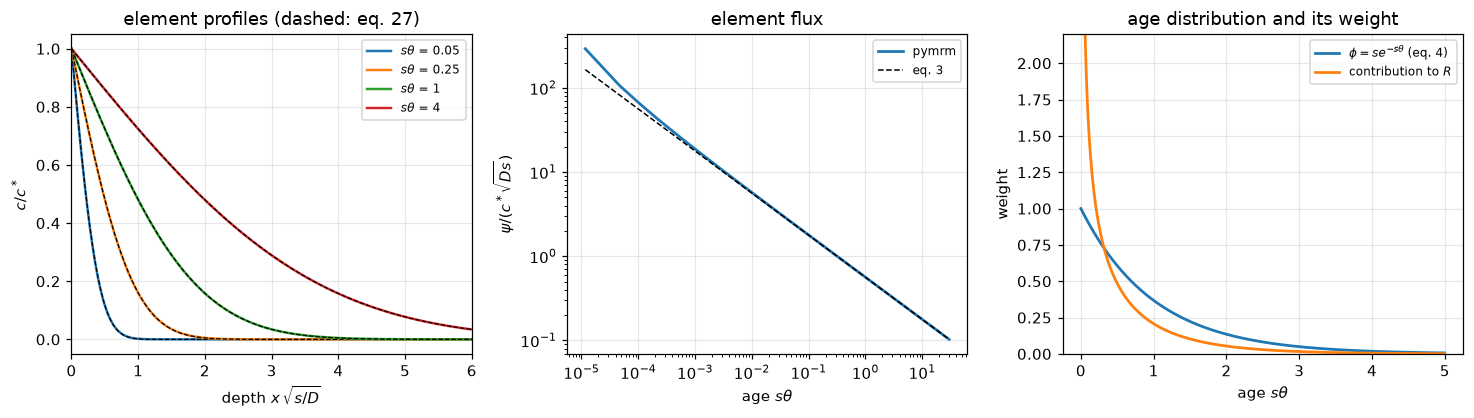

In [5]:
D, s, cstar = 1.0, 1.0, 1.0           # D = s = c* = 1: only ratios matter
NX, NT, STRETCH, DEPTH, THMAX = 400, 1600, 10.0, 45.0, 30.0   # production settings
ages = (0.05, 0.25, 1.0, 4.0)
el = Element(D=D, depth=DEPTH, n_x=NX, stretch=STRETCH)
out0 = el.march(cstar=cstar, c0=0.0, th_max=THMAX, n_t=NT, profiles_at=ages)

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.9))
for a in ages:
    th_a, c_a = out0["prof"][a]
    ax[0].plot(el.x_c, c_a, lw=1.6, label=f"$s\\theta$ = {a:g}")
    ax[0].plot(el.x_c, cstar * erfc(el.x_c / (2 * np.sqrt(D * th_a))), "k--", lw=0.8)
ax[0].set(xlim=(0, 6), xlabel="depth $x\\,\\sqrt{s/D}$", ylabel="$c/c^*$",
          title="element profiles (dashed: eq. 27)")
ax[0].legend(fontsize=8)
_m = out0["theta"] > 0
ax[1].loglog(out0["theta"][_m], out0["psi"][_m], lw=1.8, label="pymrm")
ax[1].loglog(out0["theta"][_m], cstar * np.sqrt(D / (np.pi * out0["theta"][_m])), "k--",
             lw=1.0, label="eq. 3")
ax[1].set(xlabel="age $s\\theta$", ylabel="$\\psi/(c^*\\sqrt{Ds})$", title="element flux")
ax[1].legend(fontsize=8)
tt = np.linspace(0, 5, 400)
ax[2].plot(tt, s * np.exp(-s * tt), lw=1.8, label="$\\phi = s e^{-s\\theta}$ (eq. 4)")
ax[2].plot(tt[1:], s * np.exp(-s * tt[1:]) * np.sqrt(D / (np.pi * tt[1:])), lw=1.8,
           label="contribution to $R$")
ax[2].set(xlabel="age $s\\theta$", ylabel="weight", ylim=(0, 2.2),
          title="age distribution and its weight")
ax[2].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [6]:
# The three closed forms, by the pymrm route. c_o = 0.3 so that the bulk term enters.
C0B, KS, RR = 0.3, 0.7, 2.0
CASES = {   # name: (march and element arguments, closed form)
    "8":      (dict(c0=C0B), (cstar - C0B) * np.sqrt(D * s)),
    "10, 30": (dict(c0=C0B, k=KS), (cstar - C0B) / (1 / np.sqrt(D * s) + 1 / KS)),
    "12, 34": (dict(c0=C0B, r=RR), (cstar - C0B * s / (RR + s)) * np.sqrt(D * (RR + s))),
}
RES = {k: rate(s, NT, cstar=cstar, th_max=THMAX, n_x=NX, **kw) for k, (kw, _) in CASES.items()}
e8, e10, e34 = (CASES[k][1] for k in CASES)
closed = pd.DataFrame(
    [(k, CASES[k][1], RES[k]["extrapolated"], rel(RES[k]["extrapolated"], CASES[k][1]),
      rel(RES[k]["raw"], CASES[k][1])) for k in CASES],
    columns=["eq.", "closed form", "pymrm, extrapolated", "rel. dev.", "rel. dev. raw"])
print(closed.to_string(index=False, formatters={
    "closed form": "{:.6f}".format, "pymrm, extrapolated": "{:.6f}".format,
    "rel. dev.": "{:+.2e}".format, "rel. dev. raw": "{:+.2e}".format}))
claims.value("R_vs_eq8_rel", rel(RES["8"]["extrapolated"], e8))
claims.value("R_vs_eq8_raw_rel", rel(RES["8"]["raw"], e8))
claims.value("R_vs_eq30_rel", rel(RES["10, 30"]["extrapolated"], e10))
claims.value("R_vs_eq34_rel", rel(RES["12, 34"]["extrapolated"], e34))

# eq. 13 is eq. 12 rewritten with k_L = sqrt(Ds)
kL = np.sqrt(D * s)
e13 = (cstar - C0B * s / (RR + s)) * np.sqrt(kL ** 2 + D * RR)
claims.bound("eq13_vs_eq12", abs(rel(e13, e34)), max=1e-14, basis="identity", structural=True,
             note="eq. 13 is eq. 12 with k_L = sqrt(Ds) substituted")
display(Markdown(
    f"The pymrm element reproduces all three closed forms, to "
    f"**{abs(claims['R_vs_eq8_rel']):.1e}**, **{abs(claims['R_vs_eq30_rel']):.1e}** and "
    f"**{abs(claims['R_vs_eq34_rel']):.1e}** relative after extrapolation in the age step "
    f"(raw at {NT} steps, eq. 8 is {abs(claims['R_vs_eq8_raw_rel']):.1e} off). *Validation* "
    f"shows that what is left is the grid error of the {NX}-cell grid. Eq. 13 is eq. 12 "
    f"rewritten with $k_L = \\sqrt{{Ds}}$ and agrees with it to below 1e-14 "
    f"(here {claims['eq13_vs_eq12']:.0e}): an algebraic identity, registered as one."))

   eq. closed form pymrm, extrapolated rel. dev. rel. dev. raw
     8    0.700000            0.699972 -3.97e-05     -6.82e-04
10, 30    0.288235            0.288231 -1.64e-05     -4.60e-04
12, 34    1.558846            1.558784 -3.94e-05     -8.06e-05


The pymrm element reproduces all three closed forms, to **4.0e-05**, **1.6e-05** and **3.9e-05** relative after extrapolation in the age step (raw at 1600 steps, eq. 8 is 6.8e-04 off). *Validation* shows that what is left is the grid error of the 400-cell grid. Eq. 13 is eq. 12 rewritten with $k_L = \sqrt{Ds}$ and agrees with it to below 1e-14 (here 0e+00): an algebraic identity, registered as one.

### Where the $\sqrt{D}$ exponent survives

This is the discriminating content of the paper, so it is worth being precise
about what the model actually predicts. Write

$$n \equiv \frac{d\ln k_L}{d\ln D},$$

so film theory (eq. 1) has $n = 1$ and eq. 8 has $n = \tfrac12$. The interesting
question is not "which is right" (the paper cannot answer that) but **how
fragile the $\tfrac12$ is**, because a prediction that dissolves under any
complication is not much of a prediction. The exponents below differentiate the
closed forms by a centred difference in $\ln D$; they involve no solver.

In [7]:
def local_exponent(f, D0, h=1e-4):
    """n = d ln f / d ln D by a centred difference in ln D."""
    return (np.log(f(D0 * np.exp(h))) - np.log(f(D0 * np.exp(-h)))) / (2 * h)


def R_series(D_, kS, kS_exponent=0.0):
    """Eq. 10/11 in units of c* - c_o; kS may scale as D**kS_exponent."""
    return 1 / (1 / np.sqrt(D_ * s) + 1 / (kS * D_ ** kS_exponent))


thc = 1.0                                   # uniform age distribution on (0, theta_c)
a_w, s_a = np.array([0.6, 0.3, 0.1]), np.array([0.5, 3.0, 20.0])   # a patchwork
R21_uniform = lambda D_: 2 * np.sqrt(D_ / (np.pi * thc))           # eq. 21, phi = 1/theta_c
R22 = lambda D_: np.sqrt(D_) * (a_w * np.sqrt(s_a)).sum() / a_w.sum()
exp_rows = [
    ("1", "film theory as the paper prints it", local_exponent(lambda D_: D_ / 1.0, 1.0)),
    ("8", "surface renewal, phi = s exp(-s theta)", local_exponent(lambda D_: np.sqrt(D_ * s), 1.0)),
    ("21", "uniform phi on (0, theta_c) (nonrandom packing)", local_exponent(R21_uniform, 1.0)),
    ("22", "a patchwork of three areas with their own s_a", local_exponent(R22, 1.0)),
    ("12", f"first-order reaction r/s = {RR:g}, at fixed r",
     local_exponent(lambda D_: np.sqrt(D_ * (RR + s)), 1.0)),
] + [("10, 11", f"series surface resistance k_S/sqrt(Ds) = {kk:g}",
      local_exponent(lambda D_, kk=kk: R_series(D_, kk), 1.0)) for kk in (0.1, 1.0, 10.0)]
expo = pd.DataFrame(exp_rows, columns=["eq.", "system", "n"])
print(expo.to_string(index=False, formatters={"n": "{:.5f}".format}))
for _name, _i in (("n_eq8", 1), ("n_eq21_uniform_phi", 2), ("n_eq22_patchwork", 3)):
    claims.bound(_name, exp_rows[_i][2], min=0.5 - 1e-9, max=0.5 + 1e-9, basis="identity",
                 structural=True, note="sqrt(D) factors out of the closed form; "
                 "the centred difference is exact for a power law up to round-off")
claims.bound("n_eq10_kS1", exp_rows[6][2], min=0.25 - 1e-9, max=0.25 + 1e-9, basis="theory",
             note="1/2 times the liquid share of the resistance, 1/2 at k_S = sqrt(Ds)")
print("Exponents of eqs. 8, 21 and 22 within 1e-9 of 1/2, and of eq. 10 at k_S = sqrt(Ds) "
      f"within 1e-9 of 1/4 (here {max(abs(exp_rows[i][2] - 0.5) for i in (1, 2, 3)):.0e} "
      f"and {abs(exp_rows[6][2] - 0.25):.0e})")

   eq.                                          system       n
     1              film theory as the paper prints it 1.00000
     8          surface renewal, phi = s exp(-s theta) 0.50000
    21 uniform phi on (0, theta_c) (nonrandom packing) 0.50000
    22   a patchwork of three areas with their own s_a 0.50000
    12        first-order reaction r/s = 2, at fixed r 0.50000
10, 11    series surface resistance k_S/sqrt(Ds) = 0.1 0.04545
10, 11      series surface resistance k_S/sqrt(Ds) = 1 0.25000
10, 11     series surface resistance k_S/sqrt(Ds) = 10 0.45455
Exponents of eqs. 8, 21 and 22 within 1e-9 of 1/2, and of eq. 10 at k_S = sqrt(Ds) within 1e-9 of 1/4 (here 5e-13 and 5e-13)


In [8]:
# Eq. 25: an undetermined age distribution AND a gas film. Danckwerts states that
# such a system "will show no simple relationship between R and D". Quantify it.
QUAD_TIGHT = dict(epsabs=0.0, epsrel=1e-12, limit=400)


def eq25(D_, kG, H, phi, th_max=60.0, H_squared=True, quad_kw=QUAD_TIGHT):
    """Eq. 25 in units of c* - c_o, the exponent with H**2 (eq. 29) or H (as printed)."""
    kk = kG / H
    a2 = kG ** 2 / ((H ** 2 if H_squared else H) * D_)
    f = lambda t: np.exp(min(a2 * t, 700.0)) * erfc(kk * np.sqrt(t / D_)) * phi(t)
    return kk * quad(f, 0.0, th_max, **quad_kw)[0]


def growth_rate(k, H, H_squared=False):
    """Exponential rate of eq. 25's integrand at large age, phi = s exp(-s theta)."""
    return (k * H) ** 2 / ((H ** 2 if H_squared else H) * D) - k ** 2 / D - s


phi_exp = lambda t: s * np.exp(-s * t)
phi_uni = lambda t: (1.0 / thc) if t < thc else 0.0
eq9 = lambda k: 1.0 / (1 / np.sqrt(D * s) + 1 / k)      # eq. 9/10 with k = k_G/H

# One point, chosen because the printed form diverges there.
H, kk = 5.0, 0.7
claims.bound("eq25_collapse_to_eq9", abs(rel(eq25(1.0, H * kk, H, phi_exp, 200.0), eq9(kk))),
             max=1e-13, basis="tolerance", note="quad at epsrel 1e-12")
claims.value("eq25_printed_growth_rate", growth_rate(kk, H))
trunc = {T: eq25(1.0, H * kk, H, phi_exp, T, H_squared=False) for T in (10, 20, 40)}
claims.value("eq25_printed_ratio_T40_over_T20", trunc[40] / trunc[20])
print(pd.DataFrame([(T, v, v / eq9(kk)) for T, v in trunc.items()],
                   columns=["age cut-off s theta_max", "eq. 25 as printed", "ratio to eq. 9"]
                   ).to_string(index=False, float_format="{:.4g}".format))


def hk_sweep(H_squared_collapse=True):
    rows = []
    for H_ in (1.5, 2.0, 3.0, 5.0, 10.0):
        for k_ in (0.3, 0.7, 1.5):
            sq = eq25(1.0, H_ * k_, H_, phi_exp, 200.0, H_squared=H_squared_collapse)
            p40 = eq25(1.0, H_ * k_, H_, phi_exp, 40.0, H_squared=False)
            p80 = eq25(1.0, H_ * k_, H_, phi_exp, 80.0, H_squared=False)
            rows.append((H_, k_, growth_rate(k_, H_), abs(sq / eq9(k_) - 1), p40 / eq9(k_),
                         p80 / eq9(k_)))
    return pd.DataFrame(rows, columns=["H", "k_G/H", "growth rate", "|H^2 D form / eq. 9 - 1|",
                                       "printed / eq. 9, cut at 40", "same, cut at 80"])


hkt = hk_sweep()
print(hkt.to_string(index=False, formatters={
    "growth rate": "{:+.3f}".format, "|H^2 D form / eq. 9 - 1|": lambda v: "below 1e-13",
    "printed / eq. 9, cut at 40": "{:.4g}".format, "same, cut at 80": "{:.4g}".format}))
claims.bound("eq25_collapse_worst_over_Hk", hkt["|H^2 D form / eq. 9 - 1|"].max(), max=1e-13,
             basis="tolerance", note="15 (H, k) points, quad at epsrel 1e-12")
claims.value("eq25_printed_best_dev_over_Hk",
             (hkt["printed / eq. 9, cut at 40"] - 1.0).abs().min())
claims.count("eq25_printed_divergent_points", hkt["growth rate"], 0.0, min_margin=0.01,
             note="points of the sweep where k^2(H-1) > sD")

# With a non-exponential phi the exponent is no longer 1/2 and no longer constant.
Ds_ = np.array([0.1, 0.3, 1.0, 3.0, 10.0])
n25 = {kk2: [local_exponent(lambda D_, kk2=kk2: eq25(D_, H * kk2, H, phi_uni, thc), Dv)
             for Dv in Ds_] for kk2 in (0.3, 1.0, 3.0)}
print(pd.DataFrame({f"D = {d:g}": [n25[k][i] for k in n25] for i, d in enumerate(Ds_)},
                   index=[f"k_G/H = {k:g}" for k in n25]).to_string(float_format="{:.3f}".format))
claims.value("n_eq25_uniform_phi_min", n25[0.3][-1])
claims.value("n_eq25_uniform_phi_max", n25[3.0][0])

display(Markdown(
    f"**The argument that settles the exponent of eq. 25 does not depend on where it is "
    f"evaluated.** Eq. 9 is eq. 25's own special case for the exponential age "
    f"distribution, so the corrected form must reproduce it at *every* $(H, k_G/H)$, and "
    f"over the 15-point sweep it does to below 1e-13 "
    f"(here {claims['eq25_collapse_worst_over_Hk']:.0e}), with the quadrature at a "
    f"relative tolerance of 1e-12. The printed form reproduces it **nowhere**: the "
    f"closest it comes is {100 * claims['eq25_printed_best_dev_over_Hk']:.1f} % off.\n\n"
    f"The *divergence* is the dramatic symptom, and unlike the collapse it is "
    f"**conditional**. Since $\\mathrm{{erfc}}(k\\sqrt{{\\theta/D}}) \\sim "
    f"e^{{-k^2\\theta/D}}$, the printed integrand behaves as "
    f"$\\exp\\{{[k^2(H-1)/D - s]\\theta\\}}/\\sqrt\\theta$ where the corrected one "
    f"behaves as $e^{{-s\\theta}}/\\sqrt\\theta$, so the printed integral diverges "
    f"**only when $k^2(H-1) > sD$**: at {claims['eq25_printed_divergent_points']} of "
    f"the 15 points of the sweep. At $H = {H:g}$, $k = {kk:g}$ and $D = s = 1$ that "
    f"exponent is **{claims['eq25_printed_growth_rate']:+.2f}**, and the first table "
    f"shows the printed integral growing by a factor of "
    f"{claims['eq25_printed_ratio_T40_over_T20']:.2g} when the cut-off is doubled from "
    f"20 to 40. At $k_G/H$ = 0.3 the same printed expression converges, to a finite and "
    f"wrong number; the last two columns of the sweep separate the two behaviours. So "
    f"the slip is settled from the paper's own eqs. 9 and 29, and it is reported, not "
    f"silently repaired.\n\n"
    f"The last table is the quantitative version of Danckwerts' remark that a system "
    f"with an undetermined $\\phi$ **and** a gas film shows *no simple relationship "
    f"between $R$ and $D$*: the local exponent runs from "
    f"{claims['n_eq25_uniform_phi_min']:.3f} to {claims['n_eq25_uniform_phi_max']:.3f} "
    f"across the sweep, never $\\tfrac12$ and never constant."))

 age cut-off s theta_max  eq. 25 as printed  ratio to eq. 9
                      10               2657            6452
                      20          2.807e+07       6.818e+07
                      40          4.367e+15       1.061e+16
   H  k_G/H growth rate |H^2 D form / eq. 9 - 1| printed / eq. 9, cut at 40 same, cut at 80
 1.5    0.3      -0.955              below 1e-13                      1.042           1.042
 1.5    0.7      -0.755              below 1e-13                      1.247           1.247
 1.5    1.5      +0.125              below 1e-13                      201.7       1.959e+04
 2.0    0.3      -0.910              below 1e-13                      1.087           1.087
 2.0    0.7      -0.510              below 1e-13                      1.683           1.683
 2.0    1.5      +1.250              below 1e-13                  6.196e+20       2.266e+42
 3.0    0.3      -0.820              below 1e-13                      1.191           1.191
 3.0    0.7      -0.020 

**The argument that settles the exponent of eq. 25 does not depend on where it is evaluated.** Eq. 9 is eq. 25's own special case for the exponential age distribution, so the corrected form must reproduce it at *every* $(H, k_G/H)$, and over the 15-point sweep it does to below 1e-13 (here 6e-16), with the quadrature at a relative tolerance of 1e-12. The printed form reproduces it **nowhere**: the closest it comes is 4.2 % off.

The *divergence* is the dramatic symptom, and unlike the collapse it is **conditional**. Since $\mathrm{erfc}(k\sqrt{\theta/D}) \sim e^{-k^2\theta/D}$, the printed integrand behaves as $\exp\{[k^2(H-1)/D - s]\theta\}/\sqrt\theta$ where the corrected one behaves as $e^{-s\theta}/\sqrt\theta$, so the printed integral diverges **only when $k^2(H-1) > sD$**: at 7 of the 15 points of the sweep. At $H = 5$, $k = 0.7$ and $D = s = 1$ that exponent is **+0.96**, and the first table shows the printed integral growing by a factor of 1.6e+08 when the cut-off is doubled from 20 to 40. At $k_G/H$ = 0.3 the same printed expression converges, to a finite and wrong number; the last two columns of the sweep separate the two behaviours. So the slip is settled from the paper's own eqs. 9 and 29, and it is reported, not silently repaired.

The last table is the quantitative version of Danckwerts' remark that a system with an undetermined $\phi$ **and** a gas film shows *no simple relationship between $R$ and $D$*: the local exponent runs from 0.034 to 0.455 across the sweep, never $\tfrac12$ and never constant.

**So the exponent is robust to the thing the paper worries about, and fragile
to the thing it does not dwell on.** Every complication *inside* the liquid (a
different age distribution, a patchwork of renewal rates, a first-order reaction
at fixed $r$) leaves $n = \tfrac12$ untouched, because $\sqrt{D}$ factors
straight out of eqs. 21 and 22. What breaks it is a **resistance in series** with
the liquid: a gas film, an interfacial resistance, or (below) a liquid layer thin
enough to reach steady state. Those pull $n$ down towards 0 or up towards 1, and
in eq. 25 they destroy the power law entirely.

**The rows at exactly $\tfrac12$ are algebra**, registered as structural: they
cannot fail and are evidence for nothing about the numerics. The rows that move
carry the information, and what they say is that an exponent measurement is only
interpretable when the liquid-side resistance dominates.

## Validation

Five things are checked: the six numerical statements the paper makes, the
printed closed form of eq. 36 against a quadrature of eq. 31, the transcription
of eqs. 16 and 17, the convergence of the element in **both** axes with the
closed-form deviations decomposed into grid and step error, and the two readings
of the surface flux. Under *What pymrm adds* the second-order solver gets the
same treatment, plus a case whose answer is known exactly.

### 1. Every number the paper prints

In [9]:
MU_W, RHO_W, G_CGS = 0.01, 1.0, 981.0     # water and g, CGS: NOT printed in the paper


def layer_mm(D_=D_w, theta=th_1h):
    """Equivalent saturated layer Q/(c* - c_o) = 2 sqrt(D theta / pi), in mm."""
    return 2 * np.sqrt(D_ * theta / np.pi) * 10.0


def L_film(D_=P["L_example_D"], d=P["L_example_d"], d_exp=4):
    """Falling-film criterion L = l D mu / (g rho d^4)."""
    return P["L_example_l"] * D_ * MU_W / (G_CGS * RHO_W * d ** d_exp)


def age_deficit(sthc, sqrt_arg=True):
    """1 - erf(sqrt(s theta_c)): the share of R from ages above theta_c."""
    return 1 - erf(np.sqrt(sthc) if sqrt_arg else sthc)


coef = 2 * erfcinv(frac_pen)            # eq. 27: erfc(x / 2 sqrt(D theta)) = fraction
depth_1h = P["depth_coefficient"] * np.sqrt(D_w * th_1h) * 10.0     # the paper's own 3.6
defic = age_deficit(P["sthetac_10pct"])
sthc_exact = brentq(lambda t: age_deficit(t) - 0.10, 0.1, 5.0, xtol=1e-14)
frac_old = age_deficit(P["s_packed_tower"] * P["age_cut_0p33"])
L_val = L_film()
claims.value("layer_1h_mm", layer_mm())
claims.value("depth_coefficient", coef, rtol=1e-3)
claims.value("depth_coefficient_rel", rel(coef, P["depth_coefficient"]))
claims.value("depth_1h_mm", depth_1h)
claims.value("L_falling_film", L_val)
claims.value("L_falling_film_rel", rel(L_val, P["L_example"]))
claims.value("erf_deficit_at_sthetac_1p5", defic)
claims.value("sthetac_for_exactly_10pct", sthc_exact, rtol=1e-3)
claims.value("frac_R_from_ages_over_0p33s", frac_old)
print(pd.DataFrame([
    ("layer_1h", "equivalent saturated layer at 1 h (mm)", "about 2", layer_mm()),
    ("depth_coefficient", "coefficient in depth = coef sqrt(D theta)", "3.6", coef),
    ("depth_1h", "depth of penetration at 1 h (mm), with the printed 3.6", "about 6", depth_1h),
    ("L_example", "L for the worked falling film", "about 0.05", L_val),
    ("sthetac_10pct", "deficit of erf sqrt(s theta_c) at s theta_c = 1.5", "< 10 %", defic),
    ("age_cut_0p33", "share of R from surfaces older than 0.33 s at s = 5", "< 1/10", frac_old),
], columns=["id", "quantity", "as printed", "recomputed"]).to_string(
    index=False, formatters={"recomputed": "{:.4f}".format}))

display(Markdown(f"""
All six reproduce, and three of them are looser than they look, which is worth
stating rather than rounding away.

* The **saturated layer** comes out at **{layer_mm():.3f} mm** against "about 2 mm",
  {100 * (layer_mm() / P['layer_1h'] - 1):+.0f} %.
* The **depth-of-penetration coefficient** is **{coef:.4f}** against the printed
  {P['depth_coefficient']:g}, {100 * claims['depth_coefficient_rel']:+.2f} %. It is the number
  that confirms the fraction: the sentence defining it prints a stacked "1/100" that
  the PDF text layer drops, and one-tenth would give {2 * erfcinv(0.1):.3f} instead.
* The **depth at 1 hour** is **{depth_1h:.2f} mm** using the paper's own
  {P['depth_coefficient']:g} ({coef * np.sqrt(D_w * th_1h) * 10:.2f} mm with the exact
  coefficient) against "about 6 mm", {100 * (depth_1h / P['depth_1h'] - 1):+.0f} %. Both of
  the paper's millimetre figures are **below** the value its own formula gives, so both
  are roundings *down*: {layer_mm():.3f} to "about 2" is ordinary rounding to the nearest
  millimetre, whereas {depth_1h:.2f} to "about 6" is a truncation; rounding would have
  given {round(depth_1h):.0f}. The whole of the {100 * (depth_1h / P['depth_1h'] - 1):+.0f} % is
  that truncation: {P['depth_coefficient']:g}·√(Dθ) with his own D and exposure leaves no
  freedom.
* The **falling-film criterion** gives **{L_val:.5f}** against "about 0.05",
  {100 * claims['L_falling_film_rel']:+.1f} %, with $\\mu$, $\\rho$ and $g$ supplied from
  outside the paper. That is a reconstruction, and the reading it rests on is checked
  twice over: the PDF text layer renders the printed $D$ as $10^{{-3}}$, which would give
  {L_film(D_=1e-3):.2f}, and reading the $d^{{-4}}$ as $d^{{-2}}$ would give
  {L_film(d_exp=2):.2e}.
* The **truncated age average** is short of $\\sqrt{{Ds}}$ by
  **{100 * defic:.2f} %** at $s\\theta_c$ = {P['sthetac_10pct']:g}, so "within 10 %" holds;
  the age at which the deficit is exactly 10 % is $s\\theta_c$ = **{sthc_exact:.4f}**, so
  the printed {P['sthetac_10pct']:g} is a conservative round number.
* At $s$ = {P['s_packed_tower']:g} s⁻¹, surfaces older than {P['age_cut_0p33']:g} s carry
  **{100 * frac_old:.2f} %** of the rate, so "less than one tenth" holds with room to spare.
"""))

               id                                               quantity as printed recomputed
         layer_1h                 equivalent saturated layer at 1 h (mm)    about 2     2.1409
depth_coefficient              coefficient in depth = coef sqrt(D theta)        3.6     3.6428
         depth_1h depth of penetration at 1 h (mm), with the printed 3.6    about 6     6.8305
        L_example                          L for the worked falling film about 0.05     0.0510
    sthetac_10pct      deficit of erf sqrt(s theta_c) at s theta_c = 1.5     < 10 %     0.0833
     age_cut_0p33    share of R from surfaces older than 0.33 s at s = 5     < 1/10     0.0693



All six reproduce, and three of them are looser than they look, which is worth
stating rather than rounding away.

* The **saturated layer** comes out at **2.141 mm** against "about 2 mm",
  +7 %.
* The **depth-of-penetration coefficient** is **3.6428** against the printed
  3.6, +1.19 %. It is the number
  that confirms the fraction: the sentence defining it prints a stacked "1/100" that
  the PDF text layer drops, and one-tenth would give 2.326 instead.
* The **depth at 1 hour** is **6.83 mm** using the paper's own
  3.6 (6.91 mm with the exact
  coefficient) against "about 6 mm", +14 %. Both of
  the paper's millimetre figures are **below** the value its own formula gives, so both
  are roundings *down*: 2.141 to "about 2" is ordinary rounding to the nearest
  millimetre, whereas 6.83 to "about 6" is a truncation; rounding would have
  given 7. The whole of the +14 % is
  that truncation: 3.6·√(Dθ) with his own D and exposure leaves no
  freedom.
* The **falling-film criterion** gives **0.05097** against "about 0.05",
  +1.9 %, with $\mu$, $\rho$ and $g$ supplied from
  outside the paper. That is a reconstruction, and the reading it rests on is checked
  twice over: the PDF text layer renders the printed $D$ as $10^{-3}$, which would give
  5.10, and reading the $d^{-4}$ as $d^{-2}$ would give
  5.10e-06.
* The **truncated age average** is short of $\sqrt{Ds}$ by
  **8.33 %** at $s\theta_c$ = 1.5, so "within 10 %" holds;
  the age at which the deficit is exactly 10 % is $s\theta_c$ = **1.3528**, so
  the printed 1.5 is a conservative round number.
* At $s$ = 5 s⁻¹, surfaces older than 0.33 s carry
  **6.93 %** of the rate, so "less than one tenth" holds with room to spare.


### 2. The one criterion that is a real calculation: eq. 36

Danckwerts' hardest case is the second-order reaction, for which he says "no
solution has so far been found". His way out is to substitute $r'c_o'$ for the
first-order $r$ and use eqs. 12 to 14, and eq. 36 is the condition under which he
claims that costs less than 10 %. He then illustrates it: with
$r'c_o'/s = 1$, "it is then found that $c_o'/c^* > 50$ if Equation 36 is to be
complied with".

That is a checkable arithmetic claim, and the paper prints the ratio in closed
form. Two routes are compared: the printed closed form, and numerical
quadrature of eq. 31, which is the integrand the closed form integrates.

In [10]:
EQ36_FRACTION, EQ36_LEVEL = 0.05, 0.95    # theta_c = 0.05 c_o'/(c* r'c_o') and ratio > 0.95 (eq. 36)


def eq36_ratio_closed(a, s_, thc_):
    """The ratio printed on p. 1466: erf sqrt((a+s) thc) - sqrt(a/(a+s)) e^{-s thc}
    erf sqrt(a thc), with a = r' c_o'."""
    return (erf(np.sqrt((a + s_) * thc_))
            - np.sqrt(a / (a + s_)) * np.exp(-s_ * thc_) * erf(np.sqrt(a * thc_)))


def eq36_ratio_quad(a, s_, thc_, second_term=True):
    """The same ratio by integrating eq. 31: psi = c* sqrt(D a) [erf sqrt(a th)
    + e^{-a th}/sqrt(pi a th)], over R1 = c* sqrt(D (a + s))."""
    f = lambda t: s_ * np.exp(-s_ * t) * np.sqrt(a) * (
        erf(np.sqrt(a * t)) + (np.exp(-a * t) / np.sqrt(np.pi * a * t) if second_term else 0.0))
    return quad(f, 0.0, thc_, points=[0.0], epsabs=0.0, epsrel=1e-13, limit=400)[0] / np.sqrt(a + s_)


def eq36_threshold(fraction=EQ36_FRACTION):
    """c_o'/c* at which the eq. 36 ratio equals 0.95, at r'c_o'/s = 1."""
    t = brentq(lambda t: eq36_ratio_closed(1.0, 1.0, t) - EQ36_LEVEL, 0.5, 80.0, xtol=1e-14)
    return t * 1.0 / fraction


a_, s_ = 1.0, 1.0                                     # r' c_o' / s = 1, his illustration
thc_50 = EQ36_FRACTION * P["so_ratio_threshold"] / a_
r_closed = eq36_ratio_closed(a_, s_, thc_50)
ratio_star = eq36_threshold()
claims.value("eq36_ratio_at_printed_50", r_closed, rtol=1e-4)
claims.bound("eq36_closed_vs_quadrature", abs(rel(r_closed, eq36_ratio_quad(a_, s_, thc_50))),
             max=1e-13, basis="tolerance", note="quad at epsrel 1e-13")
claims.value("eq36_threshold_c0p_over_cstar", ratio_star, rtol=1e-4)
claims.value("eq36_threshold_rel_to_printed", rel(ratio_star, P["so_ratio_threshold"]))
display(Markdown(f"""
The printed closed form and the quadrature of eq. 31 agree to below 1e-13 (here
{claims['eq36_closed_vs_quadrature']:.0e}), which certifies that the two were transcribed
consistently; they come from the same page of the paper, so this is a check of the
transcription, not of the physics.

At the printed $c_o'/c^* = {P['so_ratio_threshold']:g}$ the ratio is **{r_closed:.5f}**, and
eq. 36 demands more than {EQ36_LEVEL:g}. It is not met. The exact threshold is $c_o'/c^*$ =
**{ratio_star:.2f}** ({100 * claims['eq36_threshold_rel_to_printed']:+.0f} % on the printed
{P['so_ratio_threshold']:g}). So "$> 50$" is a rounded statement of "$> 53$", and 50 itself sits
{100 * (EQ36_LEVEL / r_closed - 1):.2f} % on the wrong side of his own criterion. It changes
nothing downstream (the second-order solve below shows the approximation is far better
than eq. 36 makes it look), but it is his arithmetic, and it is recorded.
"""))


The printed closed form and the quadrature of eq. 31 agree to below 1e-13 (here
2e-16), which certifies that the two were transcribed
consistently; they come from the same page of the paper, so this is a check of the
transcription, not of the physics.

At the printed $c_o'/c^* = 50$ the ratio is **0.94186**, and
eq. 36 demands more than 0.95. It is not met. The exact threshold is $c_o'/c^*$ =
**53.01** (+6 % on the printed
50). So "$> 50$" is a rounded statement of "$> 53$", and 50 itself sits
0.86 % on the wrong side of his own criterion. It changes
nothing downstream (the second-order solve below shows the approximation is far better
than eq. 36 makes it look), but it is his arithmetic, and it is recorded.


### 3. Eqs. 16 and 17

Eq. 16 defines $\beta$ for the instantaneous-reaction case through a
transcendental equation with four error functions in it. It cannot be checked by
substituting numbers into itself.

**Eq. 16 is the flux balance at the reaction plane.** Take the moving-front
construction (absorbed gas between the surface and a plane at
$x_f = 2\beta\sqrt{\theta}$, reagent beyond it, both concentrations zero at the
plane) and require that equivalents arrive there at equal rates. That balance,
written out, *is* eq. 16 character for character. This is a derivation, not a
test. The check that can fail is under *What pymrm adds*, where a solver that
never forms $\beta$ is asked to reach the same answer.

**Eq. 17 follows from 15 and 16 when $D' = D$**, because eq. 16 then reduces to
$\mathrm{erf}(\beta/\sqrt{D}) = c^*/(c^*+c_o')$ and the erf cancels out of eq. 15.
That is an algebraic identity, but it is not powerless against the
*transcription*: swap the erf and erfc in eq. 16 and it stops holding, except at
$c_o' = c^*$, where eq. 16 is symmetric in the two.

In [11]:
ident = []
for c0p in (0.5, 1.0, 3.0, 10.0):
    v, lam = eq15(cstar, c0p, 1.0, 1.0, 1.0)
    ident.append((c0p, v, cstar + c0p, rel(v, cstar + c0p), erf(lam), cstar / (cstar + c0p)))
idf = pd.DataFrame(ident, columns=["c_o'/c*", "eq. 15", "eq. 17", "rel. dev.",
                                   "erf(beta/sqrt(D))", "c*/(c*+c_o')"])
print(idf.to_string(index=False, formatters={
    "eq. 15": "{:.9f}".format, "eq. 17": "{:.9f}".format, "rel. dev.": lambda v: "below 1e-13",
    "erf(beta/sqrt(D))": "{:.6f}".format, "c*/(c*+c_o')": "{:.6f}".format}))
claims.bound("eq17_from_eq15_16", idf["rel. dev."].abs().max(), max=1e-13, basis="identity",
             note="eq. 16 solved by brentq at xtol 1e-15")
SWAP_C0P = 3.0
claims.value("eq17_swapped_erf_dev",
             abs(rel(eq15(cstar, SWAP_C0P, 1.0, 1.0, 1.0, swap=True)[0], cstar + SWAP_C0P)))
display(Markdown(
    f"Eq. 15 with $\\beta$ from eq. 16 returns eq. 17 to below 1e-13 (here "
    f"{claims['eq17_from_eq15_16']:.0e}): an identity, and blind to any error in the "
    f"*physics* of eq. 16. It is not blind to the transcription: swapping erf and erfc "
    f"in eq. 16 moves eq. 15 by **{100 * claims['eq17_swapped_erf_dev']:.0f} %** off "
    f"eq. 17 at $c_o'/c^*$ = {SWAP_C0P:g}."))

 c_o'/c*       eq. 15       eq. 17   rel. dev. erf(beta/sqrt(D)) c*/(c*+c_o')
     0.5  1.500000000  1.500000000 below 1e-13          0.666667     0.666667
     1.0  2.000000000  2.000000000 below 1e-13          0.500000     0.500000
     3.0  4.000000000  4.000000000 below 1e-13          0.250000     0.250000
    10.0 11.000000000 11.000000000 below 1e-13          0.090909     0.090909


Eq. 15 with $\beta$ from eq. 16 returns eq. 17 to below 1e-13 (here 2e-16): an identity, and blind to any error in the *physics* of eq. 16. It is not blind to the transcription: swapping erf and erfc in eq. 16 moves eq. 15 by **67 %** off eq. 17 at $c_o'/c^*$ = 3.

### 4. Convergence, in both axes

The age step and the grid are refined separately on the eq. 8 case with
$c_o = 0$, where the answer is $\sqrt{Ds}$ exactly. Each order is taken from
**successive differences** of three levels (`pymrm.checks.observed_orders`),
which cancel the other axis's error as long as it is the same on every rung: the
step ladder runs on the production grid, and the grid ladder uses the
step-extrapolated value at fixed step counts. The reference for the step error is
the limit of a ladder of *extrapolated* values, which converge at second order.

In [12]:
STEP_LADDER, GRID_LADDER = (200, 400, 800, 1600, 3200, 6400, 12800), (50, 100, 200, 400, 800, 1600)
# Round-off level of R, measured: the worst relative gap between the two readings of
# the surface flux of one solution (the residual of the banded solve), an upper estimate.
_o = Element(n_x=NX).march(n_t=NT, th_max=THMAX)
ROUNDOFF = float(np.max(np.abs(_o["psi"][1:] / _o["psi_face"][1:] - 1)))


def R_raw(n_x=NX, n_t=NT, **kw):
    o = Element(n_x=n_x, **{k: v for k, v in kw.items() if k in ("depth", "stretch")}).march(
        n_t=n_t, th_max=THMAX)
    return age_average(o["theta"], o["Q"], s)


def step_ladder(n_x=NX):
    cache = {n: R_raw(n_x, n) for n in STEP_LADDER}
    return observed_orders(lambda n: cache[n], STEP_LADDER), cache


def grid_ladder(n_t=NT, **kw):
    return observed_orders(lambda n: 2 * R_raw(n, 2 * n_t, **kw) - R_raw(n, n_t, **kw), GRID_LADDER)


SL, SL_R = step_ladder()
RICH_LADDER = STEP_LADDER[:-1]
RL = observed_orders(lambda n: 2 * SL_R[2 * n] - SL_R[n], RICH_LADDER)
REF_STEP = RL["extrapolated"]          # the step limit on the production grid
GL = grid_ladder()
TIME_ERR = {n: rel(SL_R[n], REF_STEP) for n in STEP_LADDER}
RICH_ERR = {n: rel(2 * SL_R[2 * n] - SL_R[n], REF_STEP) for n in RICH_LADDER}
SPACE_ERR = {n: rel(v, GL["extrapolated"]) for n, v in zip(GRID_LADDER, GL["values"])}
print(f"steps on {NX} cells (raw backward Euler, order from successive differences):")
for i, n in enumerate(STEP_LADDER):
    o = f"{SL['orders'][i - 2]:7.3f}" if i >= 2 else ""
    print(f"   n_t = {n:5d}   R = {SL_R[n]:.10f}   step error {TIME_ERR[n]:+.3e}   {o}")
print(f"extrapolated pairs 2 R(2n) - R(n): orders "
      + ", ".join(f"{o:.3f}" for o in RL["orders"]))
print(f"grid, steps extrapolated from {NT}/{2 * NT}:")
for i, n in enumerate(GRID_LADDER):
    o = f"{GL['orders'][i - 2]:7.3f}" if i >= 2 else ""
    print(f"   n_x = {n:5d}   R = {GL['values'][i]:.10f}   grid error {SPACE_ERR[n]:+.3e}   {o}")
GL_REMAINDER = abs(rel(GL["extrapolated"], 1.0) - RICH_ERR[NT])

claims.bound("time_order", SL["orders"][-1], min=0.95, max=1.05, basis="theory",
             note="backward Euler, successive differences, n_t 3200/6400/12800")
claims.bound("time_order_min", min(SL["orders"]), min=0.95, max=1.05, basis="theory",
             note="every triple from n_t = 200")
claims.bound("time_order_extrapolated", RL["orders"][-1], min=1.9, max=2.1, basis="theory",
             note="2 R(2n) - R(n), n 1600/3200/6400")
claims.bound("space_order", GL["orders"][-1], min=1.9, max=2.1, basis="theory",
             note="successive differences, n_x 400/800/1600")
claims.bound("space_order_min", min(GL["orders"]), min=1.9, max=2.1, basis="theory",
             note="every triple from n_x = 50")
claims.bound("time_ladder_finest_diff_over_roundoff",
             abs(SL_R[12800] - SL_R[6400]) / (ROUNDOFF * SL_R[12800]), min=1e3, basis="theory",
             note="finest step difference against round-off of R")
claims.bound("space_ladder_finest_diff_over_roundoff",
             abs(GL["values"][-1] - GL["values"][-2]) / (ROUNDOFF * GL["values"][-1]), min=1e3,
             basis="theory", note="finest grid difference against round-off of R")
claims.value("time_err_n1600", abs(TIME_ERR[NT]))
claims.value("space_err_n400", abs(SPACE_ERR[NX]))
claims.bound("time_err_extrapolated_n1600", abs(RICH_ERR[NT]), max=1e-6, basis="chosen",
             note="2 R(3200) - R(1600) against the limit of the extrapolated ladder")
claims.bound("grid_ladder_limit_minus_step_err", GL_REMAINDER, max=1e-8, basis="chosen",
             note="grid limit against sqrt(Ds), less the step error of its 1600/3200 pair: "
                  "what neither ladder sees (finite depth and age range)")
display(Markdown(rf"""
Observed orders: **{SL['orders'][-1]:.3f}** in the age step (backward Euler, first
order; every triple from $n_t$ = 200 within {min(SL['orders']):.3f} to
{max(SL['orders']):.3f}), **{RL['orders'][-1]:.3f}** for the extrapolated pairs, and
**{GL['orders'][-1]:.3f}** in the grid (second order on a grid stretched by $e^{{10}}$;
every triple within {min(GL['orders']):.3f} to {max(GL['orders']):.3f}).

**Which error is the larger depends on whether the step is extrapolated.** Raw, the
age step dominates: {abs(TIME_ERR[NT]):.2e} at $n_t$ = {NT}, against a grid error of
{abs(SPACE_ERR[NX]):.2e} on {NX} cells. Every production value is extrapolated, and then
the step error is below 1e-6 (here {abs(RICH_ERR[NT]):.1e} for the {NT}/{2 * NT} pair) and
**the grid error is what is left**. The grid ladder's limit agrees with $\sqrt{{Ds}}$ up
to the step error of its own pair, to below 1e-8 (here {GL_REMAINDER:.0e}): the finite
depth of the element and the finite age range are invisible at this level.
"""))

steps on 400 cells (raw backward Euler, order from successive differences):
   n_t =   200   R = 0.9948760294   step error -5.085e-03   
   n_t =   400   R = 0.9974017874   step error -2.559e-03   
   n_t =   800   R = 0.9986772215   step error -1.284e-03     0.986
   n_t =  1600   R = 0.9993180006   step error -6.428e-04     0.993
   n_t =  3200   R = 0.9996391426   step error -3.216e-04     0.997
   n_t =  6400   R = 0.9997998996   step error -1.609e-04     0.998
   n_t = 12800   R = 0.9998803243   step error -8.046e-05     0.999
extrapolated pairs 2 R(2n) - R(n): orders 2.036, 2.025, 2.016, 2.010
grid, steps extrapolated from 1600/3200:
   n_x =    50   R = 0.9974966041   grid error -2.503e-03   
   n_x =   100   R = 0.9993724097   grid error -6.271e-04   
   n_x =   200   R = 0.9998426452   grid error -1.569e-04     1.996
   n_x =   400   R = 0.9999602846   grid error -3.922e-05     1.999
   n_x =   800   R = 0.9999896995   grid error -9.806e-06     2.000
   n_x =  1600   R = 0.999


Observed orders: **0.999** in the age step (backward Euler, first
order; every triple from $n_t$ = 200 within 0.986 to
0.999), **2.010** for the extrapolated pairs, and
**2.000** in the grid (second order on a grid stretched by $e^{10}$;
every triple within 1.996 to 2.000).

**Which error is the larger depends on whether the step is extrapolated.** Raw, the
age step dominates: 6.43e-04 at $n_t$ = 1600, against a grid error of
3.92e-05 on 400 cells. Every production value is extrapolated, and then
the step error is below 1e-6 (here 4.9e-07 for the 1600/3200 pair) and
**the grid error is what is left**. The grid ladder's limit agrees with $\sqrt{Ds}$ up
to the step error of its own pair, to below 1e-8 (here 2e-11): the finite
depth of the element and the finite age range are invisible at this level.


**The same budget for every closed-form comparison on the page.** For each case
at its production settings, the grid error of the extrapolated value is estimated
from the change when the cells double (scaled by $1/(2^2-1)$), and the step
error from the change when the steps double (the extrapolated value is second
order in the step). The finite-layer cases are those of *What pymrm adds 3*.

In [13]:
COTH_DEPTHS, COTH_KW = (0.3, 1.0, 2.0, 5.0), dict(base="mixed", stretch=3.0, c0=0.0, cstar=1.0)
NT_COTH = 800


def budget(kw, n_t, exact, n_x=NX):
    """(deviation, grid error, step error) of the extrapolated rate, relative to exact."""
    e0 = rate(s, n_t, n_x=n_x, th_max=THMAX, **kw)["extrapolated"]
    eg = rate(s, n_t, n_x=2 * n_x, th_max=THMAX, **kw)["extrapolated"]
    et = rate(s, 2 * n_t, n_x=n_x, th_max=THMAX, **kw)["extrapolated"]
    return rel(e0, exact), (e0 - eg) * 4 / 3 / exact, (e0 - et) * 4 / 3 / exact


BUDGET = {f"eq. {k}": budget({"cstar": cstar, **kw}, NT, ex) for k, (kw, ex) in CASES.items()}
BUDGET.update({f"coth, z = {d:g}": budget({**COTH_KW, "depth": d}, NT_COTH, 1 / np.tanh(d))
               for d in COTH_DEPTHS})
bt_ = pd.DataFrame([(k, *v, v[0] - v[1] - v[2]) for k, v in BUDGET.items()],
                   columns=["case", "deviation", "grid error", "step error", "remainder"])
print(bt_.to_string(index=False, formatters={
    "deviation": "{:+.2e}".format, "grid error": "{:+.2e}".format,
    "step error": "{:+.2e}".format, "remainder": lambda v: "below 3e-8"}))
claims.bound("closed_forms_dev_minus_budget_worst", bt_["remainder"].abs().max(), max=3e-8,
             basis="chosen", note="deviation from the closed form less the grid and step "
             "error estimates, over the three closed forms and the four finite layers")
_ratio = (bt_["grid error"] / bt_["step error"]).abs()
claims.bound("production_grid_over_step_err_min", _ratio[:3].min(), min=10, basis="chosen",
             note="eqs. 8, 10/30, 12/34 at 400 cells, steps 1600/3200 extrapolated")
claims.value("coth_grid_over_step_err_min", _ratio[3:].min())
display(Markdown(
    f"In every case the deviation from the closed form is the grid error plus the step "
    f"error to below 3e-8 (here {bt_['remainder'].abs().max():.0e}): nothing else is left. "
    f"For the three closed forms the grid error is more than 10 times the step error "
    f"(here at least {_ratio[:3].min():.0f} times); for the finite layers at "
    f"{NT_COTH}/{2 * NT_COTH} steps the step error is a larger share, the grid error being "
    f"at least {claims['coth_grid_over_step_err_min']:.1f} times it."))

         case deviation grid error step error  remainder
        eq. 8 -3.97e-05  -3.92e-05  -4.96e-07 below 3e-8
   eq. 10, 30 -1.64e-05  -1.61e-05  -2.99e-07 below 3e-8
   eq. 12, 34 -3.94e-05  -3.93e-05  -2.15e-08 below 3e-8
coth, z = 0.3 -1.76e-07  -1.60e-07  -1.74e-08 below 3e-8
  coth, z = 1 -1.78e-06  -1.37e-06  -4.11e-07 below 3e-8
  coth, z = 2 -4.80e-06  -3.20e-06  -1.62e-06 below 3e-8
  coth, z = 5 -7.36e-06  -5.33e-06  -2.03e-06 below 3e-8


In every case the deviation from the closed form is the grid error plus the step error to below 3e-8 (here 9e-09): nothing else is left. For the three closed forms the grid error is more than 10 times the step error (here at least 54 times); for the finite layers at 800/1600 steps the step error is a larger share, the grid error being at least 2.0 times it.

**The two readings of the surface flux.** The flux that enters the age average is
the discrete mass balance; `compute_boundary_values` reads the same flux at the
surface face. In a finite-volume scheme the divergence telescopes, so the two must
agree exactly for the discrete solution; what they differ by is the residual of
the banded solve, weighted by the cell volumes (entries of the operator reach
$D/h^2 \approx 4\times10^8$ at the surface cell). This is checked on the three
kinds of element the page uses: deep, deep with a reaction, and a layer over a
well-mixed bulk.

In [14]:
def flux_gap(kw, n_t=NT, **march_kw):
    elk = Element(n_x=NX, **{k: v for k, v in kw.items() if k in ("r", "depth", "stretch", "base")})
    o = elk.march(n_t=n_t, th_max=THMAX, **{k: v for k, v in kw.items() if k in ("c0", "k")},
                  **march_kw)
    return np.max(np.abs(o["psi"][1:] / o["psi_face"][1:] - 1)), o, elk


FLUX_CASES = {"deep": dict(c0=0.0), "deep, r/s = 2": dict(c0=C0B, r=RR),
              "layer z = 1": dict(depth=1.0, base="mixed", stretch=3.0, c0=0.0)}
GAPS = {k: flux_gap(kw)[0] for k, kw in FLUX_CASES.items()}
claims.bound("psi_massbalance_vs_gradient", max(GAPS.values()), max=1e-8, basis="identity",
             note="mass balance against compute_boundary_values at the surface; "
                  "the gap is the volume-weighted residual of the banded solve")
print("mass balance against the surface face, worst over the steps: below 1e-8 in each case "
      f"(here {', '.join(f'{k} {v:.0e}' for k, v in GAPS.items())})")

# The pointwise flux of the raw march against eq. 3.
_th = out0["theta"]
exact_psi = lambda th: np.sqrt(1.0 / (np.pi * th))
_res, _res2 = _th > 1e-3, _th > 0.1
claims.value("psi_vs_eq3_resolved", np.max(np.abs(out0["psi"][_res] / exact_psi(_th[_res]) - 1)))
claims.value("psi_vs_eq3_above_0p1", np.max(np.abs(out0["psi"][_res2] / exact_psi(_th[_res2]) - 1)))


def psi_err(n_t, lo=0.1):
    """Worst relative error of the raw pointwise flux against eq. 3 for s theta > lo."""
    o = el.march(n_t=n_t, th_max=THMAX)
    m = o["theta"] > lo
    return np.max(np.abs(o["psi"][m] / exact_psi(o["theta"][m]) - 1))


_drop = psi_err(NT) / psi_err(2 * NT)
claims.bound("psi_eq3_err_drop_steps_x2", _drop, min=1.8, max=2.2, basis="theory",
             note="raw backward Euler, first order in the step")
display(Markdown(
    f"Against eq. 3 the raw pointwise flux is good to "
    f"**{100 * claims['psi_vs_eq3_above_0p1']:.2f} %** for $s\\theta > 0.1$, an error that "
    f"falls {_drop:.2f} times when the steps double (backward Euler), and only to "
    f"{100 * claims['psi_vs_eq3_resolved']:.0f} % once the first steps at "
    f"$s\\theta \\sim 10^{{-3}}$ are included. **The pointwise flux at very short ages is "
    f"not converged and no claim rests on it**; the age average is, because the "
    f"quadrature runs on the cumulative uptake, which is exactly zero at $\\theta = 0$."))

mass balance against the surface face, worst over the steps: below 1e-8 in each case (here deep 5e-10, deep, r/s = 2 4e-11, layer z = 1 2e-11)


Against eq. 3 the raw pointwise flux is good to **0.54 %** for $s\theta > 0.1$, an error that falls 2.01 times when the steps double (backward Euler), and only to 5 % once the first steps at $s\theta \sim 10^{-3}$ are included. **The pointwise flux at very short ages is not converged and no claim rests on it**; the age average is, because the quadrature runs on the cumulative uptake, which is exactly zero at $\theta = 0$.

**The base of the reacting element.** The same reacting case (eq. 12/34) with a
Dirichlet base $c = c_o$ instead of no flux, on the same grid and steps, at the
production depth and on an element 3 diffusion lengths deep. Each shift is the
difference of two solves that differ only in the base.

In [15]:
def base_shift(depth, r=RR, **kw):
    """Rate with a Dirichlet base relative to the no-flux base, same grid and steps."""
    args = dict(c0=C0B, r=r, depth=depth, stretch=STRETCH, th_max=THMAX, n_x=NX)
    dirichlet = rate(s, NT, base="mixed", **args, **kw)["extrapolated"]
    noflux = rate(s, NT, base="deep", **args)["extrapolated"]
    return rel(dirichlet, noflux)


SHIFT45, SHIFT3 = base_shift(DEPTH), base_shift(3.0)
claims.bound("dirichlet_base_shift_depth45", abs(SHIFT45), max=1e-9, basis="chosen",
             note="45 diffusion lengths: the base face is out of reach of the surface")
claims.value("dirichlet_base_shift_depth3", SHIFT3)
display(Markdown(
    f"At {DEPTH:g} diffusion lengths the two bases give the same rate to below 1e-9 "
    f"(here {abs(SHIFT45):.0e}); on an element 3 deep the Dirichlet base changes it by "
    f"**{SHIFT3:+.2e}**. The no-flux base is the right truncation of a semi-infinite "
    f"liquid, and at the production depth the choice does not matter."))

At 45 diffusion lengths the two bases give the same rate to below 1e-9 (here 2e-15); on an element 3 deep the Dirichlet base changes it by **-2.34e-03**. The no-flux base is the right truncation of a semi-infinite liquid, and at the production depth the choice does not matter.

## What pymrm adds

### 1. The case Danckwerts says he could not solve

Of the second-order reaction (dissolved gas $A$ reacting with dissolved reagent
$B$ at rate $r'cc'$) he writes: *"These equations are nonlinear and no solution
has so far been found."* He substitutes $r'c_o'$ for $r$, uses the first-order
result, and bounds the error with eq. 36.

`TwoSpeciesElement` in `model.py` solves the coupled nonlinear pair directly, so
the bound can be measured instead of assumed. The state is `(n_x, 2)`, fields
last; the diffusion operator with one diffusivity per field
(`construct_coefficient_matrix` on the faces) is assembled once; each age step is
one `newton` solve with the analytic Jacobian of the pointwise source, a 2×2 block
per cell assembled with `construct_coefficient_matrix`, and the unknowns scaled
per field by $(c^*, c_o')$. A step whose `newton` call does not report success
raises. B is non-volatile: $\partial c_B/\partial n = 0$ at the surface.

The march is backward Euler in the age step and second order in the grid, and
both errors matter here, so every second-order number below is extrapolated in
the step ($n_t$ = 400/800) **and** in the grid (250 and 500 cells, second order),
with the less refined values printed beside it.

In [16]:
_el2 = TwoSpeciesElement(rp=1.0 / 50.0)
_c = np.random.default_rng(0).uniform(0.1, 1.0, _el2.shape) * np.array([1.0, 50.0])
JAC_CHECK = check_jacobian(lambda cf: _el2.source(cf.reshape(_el2.shape), 50.0), _c)
claims.bound("so_source_jacobian_vs_fd", JAC_CHECK["max_rel_error"], max=1e-6, basis="tolerance",
             note="pymrm.checks.check_jacobian, central differences at eps^(1/3)")
print(f"analytic source Jacobian against central differences: below 1e-6 "
      f"(here {JAC_CHECK['max_rel_error']:.0e})")

R1_PFO = np.sqrt(D * (1.0 + s))         # eq. 12 with r = r' c_o' = s, c_o = 0
NX2, NT2 = 250, 400


def so_rate(c0p, ratio, n_x=NX2, n_t=NT2, **kw):
    """Second-order rate, extrapolated in the step at n_x and 2 n_x, then in the grid."""
    a = rate_second_order(c0p, ratio, n_x=n_x, n_t=n_t, **kw)
    b = rate_second_order(c0p, ratio, n_x=2 * n_x, n_t=n_t, **kw)
    return {"raw": a["raw"], "step": a["extrapolated"], "step_fine": b["extrapolated"],
            "full": b["extrapolated"] + (b["extrapolated"] - a["extrapolated"]) / 3,
            "nit": a["nit"] + b["nit"]}


pct = lambda R: 100 * (R1_PFO / R - 1)
SWEEP = {c0p: so_rate(c0p, 1.0) for c0p in (1.0, 2.0, 5.0, 10.0, 25.0, 50.0, 100.0)}
sw = pd.DataFrame([(c0p, o["full"], pct(o["full"]), pct(o["step"]), pct(o["raw"]))
                   for c0p, o in SWEEP.items()],
                  columns=["c_o'/c*", "pymrm", "error of eq. 12 (%)",
                           f"step only, {NX2} cells (%)", f"raw, {NX2} cells, n_t = {NT2} (%)"])
print(sw.to_string(index=False, float_format="{:+.4f}".format))
ALLNITS = [n for o in SWEEP.values() for n in o["nit"]]
claims.value("so_err_at_printed_50_pct", pct(SWEEP[50.0]["full"]), rtol=0.01)
claims.value("so_err_at_ratio_1_pct", pct(SWEEP[1.0]["full"]), rtol=0.01)
claims.value("so_err_at_printed_50_raw_pct", pct(SWEEP[50.0]["raw"]))
claims.value("so_err_at_printed_50_step_only_pct", pct(SWEEP[50.0]["step"]), rtol=0.01)
N_BELOW_1 = claims.count("so_sweep_points_below_1pct", [pct(o["full"]) for o in SWEEP.values()],
                         1.0, above=False, min_margin=0.01,
                         note="sweep points c_o'/c* = 1 to 100 where eq. 12 is within 1 %")
claims.value("so_err_at_c0p_10_pct", pct(SWEEP[10.0]["full"]), rtol=0.01)
claims.value("so_err_at_c0p_2_pct", pct(SWEEP[2.0]["full"]), rtol=0.01)
claims.exact("so_newton_iters_max", int(max(ALLNITS)))
print(f"Newton iterations {min(ALLNITS)} to {max(ALLNITS)} per step")

analytic source Jacobian against central differences: below 1e-6 (here 2e-08)


  c_o'/c*   pymrm  error of eq. 12 (%)  step only, 250 cells (%)  raw, 250 cells, n_t = 400 (%)
  +1.0000 +1.2995              +8.8245                   +8.8355                        +9.0262
  +2.0000 +1.3490              +4.8320                   +4.8426                        +4.9920
  +5.0000 +1.3860              +2.0376                   +2.0479                        +2.1642
 +10.0000 +1.3997              +1.0363                   +1.0465                        +1.1501
 +25.0000 +1.4083              +0.4188                   +0.4289                        +0.5246
 +50.0000 +1.4112              +0.2102                   +0.2203                        +0.3133
+100.0000 +1.4127              +0.1055                   +0.1155                        +0.2071
Newton iterations 2 to 3 per step


**Before reading those numbers, the case whose answer is known.** A break table
perturbs an *input* and watches a number move; none of its rows can catch a
baseline that is wrong rather than insensitive. The error of eq. 12 is a
difference between two numbers, one of which comes out of a march. So run the
same solver where the answer is known: at $c_o'/c^* = 10^6$ the reagent cannot be
depleted, the problem is pseudo-first-order, and the answer is $\sqrt{D(r+s)} =
\sqrt2$. Whatever the solver reports there is discretisation.

In [17]:
CTRL = so_rate(1e6, 1.0)
ctrl = pd.DataFrame([(f"raw, {NX2} cells, n_t = {NT2}", pct(CTRL["raw"])),
                     (f"extrapolated in the step, {NX2} cells", pct(CTRL["step"])),
                     (f"extrapolated in the step, {2 * NX2} cells", pct(CTRL["step_fine"])),
                     ("extrapolated in the step and the grid", pct(CTRL["full"]))],
                    columns=["control, c_o'/c* = 1e6", "apparent error (%)"])
print(ctrl.to_string(index=False, formatters={"apparent error (%)": "{:+.5f}".format}))
claims.value("so_control_raw_n400_pct", pct(CTRL["raw"]))
claims.value("so_control_extrap_pct", pct(CTRL["step"]))
claims.bound("so_control_full_pct", abs(pct(CTRL["full"])), max=2e-3, basis="chosen",
             note="what is left of the discretisation after both extrapolations, in %")
display(Markdown(f"""
At {NX2} cells and $n_t$ = {NT2} the solver invents
**{claims['so_control_raw_n400_pct']:+.4f} %** out of the discretisation alone.
Extrapolation in the step leaves **{claims['so_control_extrap_pct']:+.4f} %**, which is the
grid error of {NX2} cells: it falls to {pct(CTRL['step_fine']):+.4f} % on {2 * NX2} cells,
and extrapolation in both leaves less than 0.002 % (here {claims['so_control_full_pct']:.0e}).
That is why the numbers above are extrapolated in both axes. At $c_o'/c^* = 50$ the
step-only value, {claims['so_err_at_printed_50_step_only_pct']:+.4f} %, carries that grid
error; extrapolated in both it is {claims['so_err_at_printed_50_pct']:+.4f} %.
"""))

               control, c_o'/c* = 1e6 apparent error (%)
            raw, 250 cells, n_t = 400           +0.10059
  extrapolated in the step, 250 cells           +0.01038
  extrapolated in the step, 500 cells           +0.00284
extrapolated in the step and the grid           +0.00033



At 250 cells and $n_t$ = 400 the solver invents
**+0.1006 %** out of the discretisation alone.
Extrapolation in the step leaves **+0.0104 %**, which is the
grid error of 250 cells: it falls to +0.0028 % on 500 cells,
and extrapolation in both leaves less than 0.002 % (here 3e-04).
That is why the numbers above are extrapolated in both axes. At $c_o'/c^* = 50$ the
step-only value, +0.2203 %, carries that grid
error; extrapolated in both it is +0.2102 %.


In [18]:
LEVEL = 10.0      # the paper's 10 % bound on the substitution's error


def err_full(c0p, **kw):
    return pct(so_rate(c0p, 1.0, **kw)["full"])


def err_raw(c0p):
    return pct(rate_second_order(c0p, 1.0, n_x=NX2, n_t=NT2)["raw"])


C0P_10 = brentq(lambda c: err_full(c) - LEVEL, 0.7, 1.0, xtol=1e-4)
claims.value("so_10pct_point_c0p_over_cstar", C0P_10, rtol=0.01)
claims.value("eq36_conservative_factor", ratio_star / C0P_10, rtol=0.01)
display(Markdown(f"""
**Danckwerts' 10 % bound holds and is conservative.** At his own illustrative point
($r'c_o'/s = 1$, $c_o'/c^* = 50$) the pseudo-first-order substitution is in error by
**{claims['so_err_at_printed_50_pct']:+.2f} %**, not 10 % (raw, at {NX2} cells and
$n_t$ = {NT2}, it reads {claims['so_err_at_printed_50_raw_pct']:+.2f} %). The error reaches
10 % at $c_o'/c^*$ = **{C0P_10:.3f}** (root-found). It is below 1 % at {N_BELOW_1} of the
{len(SWEEP)} points of the sweep, from $c_o'/c^*$ = 25 upward; at 10 it is
{claims['so_err_at_c0p_10_pct']:.2f} % and at 2 it is {claims['so_err_at_c0p_2_pct']:.2f} %.

That is not a defect in his reasoning: eq. 36 is a *sufficient* condition built by
bounding a truncated integral by a chain of inequalities, and a chain of bounds is
loose by construction. What the exact solve adds is the size of the looseness: his
criterion demands $c_o'/c^*$ above {ratio_star:.2f} where the error actually reaches 10 %
at {C0P_10:.3f}, a factor of **{claims['eq36_conservative_factor']:.0f}** in the concentration
ratio. Read the other way, at $r'c_o'/s = 1$, where "diffusion and reaction play
roughly equal parts" (the regime he says interest centres on), the substitution he
offers as a last resort is within 10 % for any reagent excess above {C0P_10:.2f} and
within 1 % once the excess is a few tens.
"""))


**Danckwerts' 10 % bound holds and is conservative.** At his own illustrative point
($r'c_o'/s = 1$, $c_o'/c^* = 50$) the pseudo-first-order substitution is in error by
**+0.21 %**, not 10 % (raw, at 250 cells and
$n_t$ = 400, it reads +0.31 %). The error reaches
10 % at $c_o'/c^*$ = **0.856** (root-found). It is below 1 % at 3 of the
7 points of the sweep, from $c_o'/c^*$ = 25 upward; at 10 it is
1.04 % and at 2 it is 4.83 %.

That is not a defect in his reasoning: eq. 36 is a *sufficient* condition built by
bounding a truncated integral by a chain of inequalities, and a chain of bounds is
loose by construction. What the exact solve adds is the size of the looseness: his
criterion demands $c_o'/c^*$ above 53.01 where the error actually reaches 10 %
at 0.856, a factor of **62** in the concentration
ratio. Read the other way, at $r'c_o'/s = 1$, where "diffusion and reaction play
roughly equal parts" (the regime he says interest centres on), the substitution he
offers as a last resort is within 10 % for any reagent excess above 0.86 and
within 1 % once the excess is a few tens.


### 2. A second route to eqs. 15 and 16

The instantaneous-reaction result is the one place in the paper where the answer
depends on a transcendental equation with four error functions. The second-order
solver never forms $\beta$, never evaluates an error function, and does not know
eq. 15 exists, so driving $r'c_o'/s$ high and landing on eq. 15 is a check that
**can** fail, unlike the eq. 15 to eq. 17 collapse above.

**Where the three rows are evaluated matters.** At $c_o' = c^*$ *and* $D' = D$
eq. 16 is symmetric in erf and erfc: reading it the wrong way round gives the
identical target, so a row there cannot see the one transcription error this test
exists to catch. The $D'/D = 1$ row is therefore run at $c_o'/c^* = 3$, and all
three rows move under the swap (break table).

In [19]:
NX_I, NT_I = 350, 600
INST_ROWS = ((0.5, 1.0), (1.0, 3.0), (2.0, 1.0))
inst = {}
for Dp, c0p in INST_ROWS:
    tgt, lam = eq15(cstar, c0p, 1.0, Dp, 1.0)
    inst[(Dp, c0p)] = (so_rate(c0p, 3000.0, n_x=NX_I, n_t=NT_I, Dp=Dp), tgt, lam)
inf = pd.DataFrame([(Dp, c0p, lam, tgt, o["full"], 100 * rel(o["full"], tgt),
                     100 * rel(o["step"], tgt), 100 * rel(o["raw"], tgt))
                    for (Dp, c0p), (o, tgt, lam) in inst.items()],
                   columns=["D'/D", "c_o'/c*", "beta/sqrt(D), eq. 16", "eq. 15",
                            "pymrm, r'c_o'/s = 3000", "dev. (%)", f"step only, {NX_I} cells (%)",
                            f"raw, n_t = {NT_I} (%)"])
print(inf.to_string(index=False, float_format="{:.5f}".format))
claims.value("inst_vs_eq15_worst_pct", inf["dev. (%)"].abs().max(), rtol=0.01)
claims.value("inst_vs_eq15_worst_raw_pct", inf[f"raw, n_t = {NT_I} (%)"].abs().max())
claims.count("inst_rows_below_eq15", inf["dev. (%)"], 0.0, above=False, min_margin=5e-4,
             note="dev. in %; the closest row is D'/D = 2, whose step error is about 2e-4 %")

# Is the residue the finite reaction rate? Push the rate at the worst row.
Dp_w, c0p_w = INST_ROWS[int(np.argmax(inf["dev. (%)"].abs().values))]
tgt_w = inst[(Dp_w, c0p_w)][1]
RATIO_ROWS = {3000.0: inst[(Dp_w, c0p_w)][0]["full"]}
for ratio in (300.0, 10000.0):
    RATIO_ROWS[ratio] = so_rate(c0p_w, ratio, n_x=NX_I, n_t=NT_I, Dp=Dp_w)["full"]
rt = pd.DataFrame(sorted((r, v, 100 * rel(v, tgt_w)) for r, v in RATIO_ROWS.items()),
                  columns=["r'c_o'/s", "pymrm", "dev. from eq. 15 (%)"])
print(rt.to_string(index=False, float_format="{:.5f}".format))
claims.value("inst_dev_at_ratio_300_pct", 100 * rel(RATIO_ROWS[300.0], tgt_w), rtol=0.01)
claims.value("inst_dev_at_ratio_10000_pct", 100 * rel(RATIO_ROWS[10000.0], tgt_w), rtol=0.01)
display(Markdown(
    f"Worst deviation **{claims['inst_vs_eq15_worst_pct']:.3f} %** across the three rows, "
    f"extrapolated in the step and in the grid (raw at $n_t$ = {NT_I} the worst row reads "
    f"{claims['inst_vs_eq15_worst_raw_pct']:.2f} %), with all "
    f"{claims['inst_rows_below_eq15']} rows below eq. 15 (the $D'/D = 2$ row only just). The second table is the reason "
    f"it may be called a residue rather than a disagreement: at the worst row the "
    f"deviation is one-signed and falls from "
    f"{abs(claims['inst_dev_at_ratio_300_pct']):.2f} % at $r'c_o'/s$ = 300 to "
    f"{abs(claims['inst_dev_at_ratio_10000_pct']):.3f} % at 10000, the finite-rate approach "
    f"to an instantaneous reaction from below. The two routes share the equations, not "
    f"the arithmetic: this is what tests the reading of eq. 16, while the eq. 17 identity "
    f"tests only that eq. 16 was copied as a flux balance."))

   D'/D  c_o'/c*  beta/sqrt(D), eq. 16  eq. 15  pymrm, r'c_o'/s = 3000  dev. (%)  step only, 350 cells (%)  raw, n_t = 600 (%)
0.50000  1.00000               0.52752 1.83707                 1.83545  -0.08847                  -0.09379            -0.24012
1.00000  3.00000               0.22531 4.00000                 3.98081  -0.47972                  -0.48485            -0.64896
2.00000  1.00000               0.41328 2.26712                 2.26709  -0.00128                  -0.00630            -0.18753


   r'c_o'/s   pymrm  dev. from eq. 15 (%)
  300.00000 3.83398              -4.15049
 3000.00000 3.98081              -0.47972
10000.00000 3.99415              -0.14627


Worst deviation **0.480 %** across the three rows, extrapolated in the step and in the grid (raw at $n_t$ = 600 the worst row reads 0.65 %), with all 3 rows below eq. 15 (the $D'/D = 2$ row only just). The second table is the reason it may be called a residue rather than a disagreement: at the worst row the deviation is one-signed and falls from 4.15 % at $r'c_o'/s$ = 300 to 0.146 % at 10000, the finite-rate approach to an instantaneous reaction from below. The two routes share the equations, not the arithmetic: this is what tests the reading of eq. 16, while the eq. 17 identity tests only that eq. 16 was copied as a flux balance.

### 3. Film theory and surface renewal are two ends of one calculation

Danckwerts states a condition for treating a liquid layer of restricted depth as
semi-infinite, "the time of exposure should be so short that the depth of
penetration is less than the depth of the liquid", and leaves it there. The
element solver can impose the other boundary: a layer of depth $d$ over a
well-mixed bulk held at $c_o$, with the surface still renewed at rate $s$.

Solving that in Laplace space gives a closed form the paper does not contain,

$$k_L = \sqrt{Ds}\,\coth\!\left(d\sqrt{s/D}\right)
 \;\Longrightarrow\;
 n = \frac{d\ln k_L}{d\ln D} = \frac12 + \frac{z}{\sinh 2z},\qquad z = d\sqrt{s/D},$$

whose two limits are **eq. 8** ($z\to\infty$, $k_L\to\sqrt{Ds}$, $n\to\tfrac12$)
and **eq. 1** ($z\to 0$, $k_L \to D/d$, $n\to 1$, with $x_L = d$). The film
picture is not a rival to surface renewal here; it is what surface renewal
becomes when the renewal is too slow to matter. The pymrm element reproduces the
closed form (its grid and step errors are in the budget of *Validation 4*).

 z = d sqrt(s/D) pymrm k_L/sqrt(Ds)   coth z rel. dev.
             0.3           3.432738 3.432738  -1.8e-07
             1.0           1.313033 1.313035  -1.8e-06
             2.0           1.037310 1.037315  -4.8e-06
             5.0           1.000083 1.000091  -7.4e-06


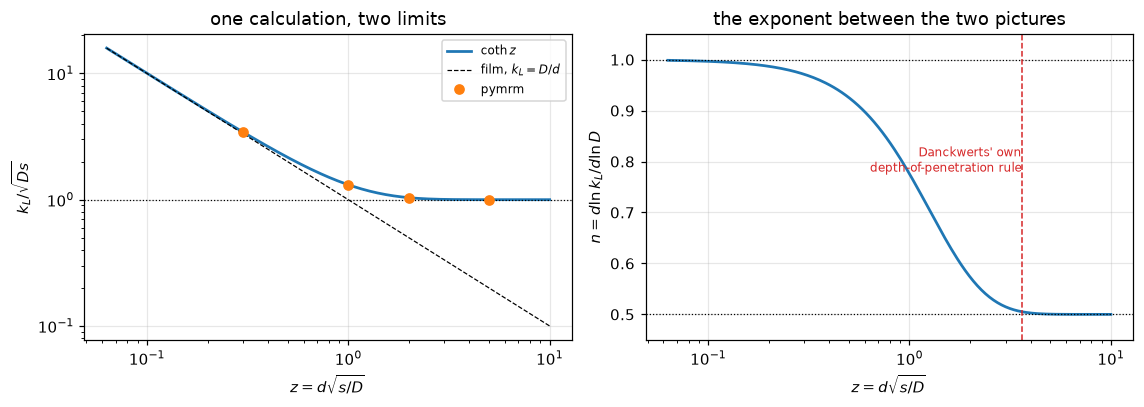


pymrm reproduces $\coth z$ to **7.4e-06** over the crossover,
the grid and step errors of 400 cells and 800/1600 steps. The exponent is
half-way between the two theories at $z$ = **1.089**, and within 10 % of
$\tfrac12$ only beyond $z$ = **2.250**.

The vertical line is Danckwerts' own criterion, read as a number: he defines the depth
of penetration as 3.6$\sqrt{D\theta}$ and asks that it be smaller
than the depth of the liquid, which at the mean age $\theta = 1/s$ is $z >
3.6$. At that $z$ the exponent is **0.5054**, within
1.1 % of $\tfrac12$, so his rule of thumb is conservative for
the purpose he states it for.


In [20]:
def n_layer(z, two=2.0):
    """Exponent of k_L = sqrt(Ds) coth z in D: 1/2 + z/sinh(2 z)."""
    return 0.5 + z / np.sinh(two * z)


z_grid = np.logspace(-1.2, 1.0, 220)
COTH = {d: rate(s, NT_COTH, n_x=NX, th_max=THMAX, depth=d, **COTH_KW) for d in COTH_DEPTHS}
ck = pd.DataFrame([(d, COTH[d]["extrapolated"], 1 / np.tanh(d),
                    rel(COTH[d]["extrapolated"], 1 / np.tanh(d))) for d in COTH_DEPTHS],
                  columns=["z = d sqrt(s/D)", "pymrm k_L/sqrt(Ds)", "coth z", "rel. dev."])
print(ck.to_string(index=False, formatters={"pymrm k_L/sqrt(Ds)": "{:.6f}".format,
                                            "coth z": "{:.6f}".format,
                                            "rel. dev.": "{:+.1e}".format}))
claims.value("kL_coth_worst_rel", ck["rel. dev."].abs().max())
z_075 = brentq(lambda z: n_layer(z) - 0.75, 0.01, 10.0, xtol=1e-14)
z_055 = brentq(lambda z: n_layer(z) - 0.55, 0.01, 10.0, xtol=1e-14)
n_at_36 = n_layer(P["depth_coefficient"])
claims.value("z_at_n_0p75", z_075, rtol=1e-4)
claims.value("z_at_n_0p55", z_055, rtol=1e-4)
claims.value("n_at_z_3p6", n_at_36, rtol=1e-4)

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax[0].loglog(z_grid, 1 / np.tanh(z_grid), lw=1.8, label="$\\coth z$")
ax[0].loglog(z_grid, 1 / z_grid, "k--", lw=0.8, label="film, $k_L = D/d$")
ax[0].axhline(1.0, color="k", ls=":", lw=0.8)
ax[0].plot(ck["z = d sqrt(s/D)"], ck["pymrm k_L/sqrt(Ds)"], "o", ms=6, label="pymrm")
ax[0].set(xlabel="$z = d\\sqrt{s/D}$", ylabel="$k_L/\\sqrt{Ds}$",
          title="one calculation, two limits"); ax[0].legend(fontsize=8)
ax[1].semilogx(z_grid, n_layer(z_grid), lw=1.8)
ax[1].axhline(0.5, color="k", ls=":", lw=0.8); ax[1].axhline(1.0, color="k", ls=":", lw=0.8)
ax[1].axvline(P["depth_coefficient"], color="C3", ls="--", lw=1.0)
ax[1].annotate("Danckwerts' own\ndepth-of-penetration rule", (P["depth_coefficient"], 0.78),
               fontsize=8, color="C3", ha="right")
ax[1].set(xlabel="$z = d\\sqrt{s/D}$", ylabel="$n = d\\ln k_L/d\\ln D$",
          ylim=(0.45, 1.05), title="the exponent between the two pictures")
fig.tight_layout(); plt.show()

display(Markdown(f"""
pymrm reproduces $\\coth z$ to **{claims['kL_coth_worst_rel']:.1e}** over the crossover,
the grid and step errors of {NX} cells and {NT_COTH}/{2 * NT_COTH} steps. The exponent is
half-way between the two theories at $z$ = **{z_075:.3f}**, and within 10 % of
$\\tfrac12$ only beyond $z$ = **{z_055:.3f}**.

The vertical line is Danckwerts' own criterion, read as a number: he defines the depth
of penetration as {P['depth_coefficient']:g}$\\sqrt{{D\\theta}}$ and asks that it be smaller
than the depth of the liquid, which at the mean age $\\theta = 1/s$ is $z >
{P['depth_coefficient']:g}$. At that $z$ the exponent is **{n_at_36:.4f}**, within
{100 * (n_at_36 / 0.5 - 1):.1f} % of $\\tfrac12$, so his rule of thumb is conservative for
the purpose he states it for.
"""))

### 4. And the thing pymrm cannot add: a test

The $\sqrt{D}$ exponent is falsifiable and the paper contains nothing that could
falsify it. It is worth being exact about why, because "no data" understates it.

Danckwerts obtains his one physical number, $s \sim 5$ s⁻¹, from published $k_L$
for CO₂ in water. He writes only that they are "calculated from published values
of $k_L$"; that the calculation is **the inversion of $k_L = \sqrt{Ds}$** is an
inference (eq. 8 is the only relation in the paper joining the two, and the
number below is what it implies), and it is labelled one rather than asserted.
Film theory fits the same single measurement exactly as well, by inverting
$k_L = D/x_L$. Both models have one free parameter and one datum: **both
residuals are zero, for any $k_L$ whatever.** No amount of care with a single
system can separate them.

In [21]:
def ratio_needed(eps, nsig=3.0, two_points=True):
    """D2/D1 for an n = 1 vs n = 1/2 separation at nsig sigma, from two k_L each with
    relative scatter eps: sigma_n = sqrt(2) eps / ln(D2/D1)."""
    return float(np.exp(nsig * (np.sqrt(2) if two_points else 1.0) * eps / 0.5))


s_paper = P["s_packed_tower"]
kL_implied = np.sqrt(D_w * s_paper)                 # cm/s
xL_film_um = D_w / kL_implied * 1e4                 # micrometres
claims.value("kL_implied_by_s5_cm_s", kL_implied)
claims.value("xL_film_equivalent_um", xL_film_um)
claims.value("D_ratio_needed_3sigma_5pct", ratio_needed(0.05))
print(pd.DataFrame([(e, ratio_needed(e)) for e in (0.02, 0.05, 0.10, 0.20)],
                   columns=["1 sigma scatter on k_L", "D2/D1 needed for a 3 sigma separation"]
                   ).to_string(index=False, float_format="{:.2f}".format))
display(Markdown(f"""
At $s$ = {s_paper:g} s⁻¹ and $D$ = {D_w:g} cm²/s the implied coefficient is
$k_L$ = **{kL_implied:.3e} cm/s**, and the film thickness that reproduces the same number
is $x_L$ = **{xL_film_um:.1f} µm**. Two models, two fitted constants, one measurement,
zero residual each.

Separating them needs at least two solutes at the same hydrodynamics, which is precisely
the comparison Danckwerts recommends ("$k_L$ should be proportional to $\\sqrt{{D}}$ for a
series of solutes") and precisely the one he does not carry out. The table says how
demanding it is: at a 5 % scatter on each $k_L$ the two diffusivities must differ by a
factor of **{ratio_needed(0.05):.2f}** before the exponents are three standard deviations
apart. His eq. 6 gives the sharper version of the same experiment (with an
eddy-diffusion resistance beneath the surface, $1/k_L$ is linear in $1/\\sqrt{{D}}$ under
renewal and in $1/D$ under a film), and it too is left for someone else.

**So this page reproduces a theory and tests its internal arithmetic. It does not test
the theory, and neither did the paper.** Danckwerts closes by saying so: the two
questions he raises "can be answered only by experiment".
"""))

 1 sigma scatter on k_L  D2/D1 needed for a 3 sigma separation
                   0.02                                   1.18
                   0.05                                   1.53
                   0.10                                   2.34
                   0.20                                   5.46



At $s$ = 5 s⁻¹ and $D$ = 1e-05 cm²/s the implied coefficient is
$k_L$ = **7.071e-03 cm/s**, and the film thickness that reproduces the same number
is $x_L$ = **14.1 µm**. Two models, two fitted constants, one measurement,
zero residual each.

Separating them needs at least two solutes at the same hydrodynamics, which is precisely
the comparison Danckwerts recommends ("$k_L$ should be proportional to $\sqrt{D}$ for a
series of solutes") and precisely the one he does not carry out. The table says how
demanding it is: at a 5 % scatter on each $k_L$ the two diffusivities must differ by a
factor of **1.53** before the exponents are three standard deviations
apart. His eq. 6 gives the sharper version of the same experiment (with an
eddy-diffusion resistance beneath the surface, $1/k_L$ is linear in $1/\sqrt{D}$ under
renewal and in $1/D$ under a film), and it too is left for someone else.

**So this page reproduces a theory and tests its internal arithmetic. It does not test
the theory, and neither did the paper.** Danckwerts closes by saying so: the two
questions he raises "can be answered only by experiment".


### 5. The break table

Each row re-runs the affected computation with one thing deliberately wrong,
injected through an argument, an input or a formula, and hands the result to
`claims.breaks`, which records whether that claim's own check fails. Rows that do
not fail their claim are printed too. The structural claims (eq. 13 against
eq. 12, and the exponents of eqs. 8, 21 and 22) differentiate or rewrite closed
forms that $\sqrt D$ factors out of; no error in the numerics can move them, and
they say nothing about the numerics either.

In [22]:
# ---- the element and its closed forms
_lab = "surface Robin condition with the sign of b flipped"
brk(_lab, "R_vs_eq30_rel", rel(rate(s, NT, c0=C0B, k=KS, bc_sign=-1.0)["extrapolated"], e10))
_lab = "reacting element with a Dirichlet base, its outflow read from the last cell centre"
brk(_lab, "R_vs_eq34_rel", rel(rate(s, NT, c0=C0B, r=RR, base="mixed", base_flux="cell")["extrapolated"], e34))
brk(_lab, "dirichlet_base_shift_depth45", abs(base_shift(DEPTH, base_flux="cell")))
brk("element 3 deep without reaction (r = 0)",
    "dirichlet_base_shift_depth3", base_shift(3.0, r=0.0))
_lab = "surface flux read as accumulation only (reaction dropped from the balance)"
brk(_lab, "R_vs_eq34_rel", rel(rate(s, NT, c0=C0B, r=RR, drop_reaction_in_flux=True)["extrapolated"], e34))
brk(_lab, "psi_massbalance_vs_gradient", flux_gap(FLUX_CASES["deep, r/s = 2"], drop_reaction_in_flux=True)[0])
_lab = "layer z = 1: base outflow read from the last cell centre, not the face"
brk(_lab, "psi_massbalance_vs_gradient", flux_gap(FLUX_CASES["layer z = 1"], base_flux="cell")[0])
_P = el.march(n_t=NT, th_max=THMAX, keep_profiles=True)
_psi_cc = -D * (_P["profiles"][0] - cstar) / el.x_c[0]
brk("surface flux read from the first cell centre, -D (c_1 - c*)/x_1, not compute_boundary_values",
    "psi_massbalance_vs_gradient", np.max(np.abs(_P["psi"][1:] / _psi_cc - 1)))
_th_cut = P["sthetac_10pct"]
_o = el.march(c0=C0B, th_max=_th_cut, n_t=NT)
brk(f"age integral truncated at s theta_c = {_th_cut:g}", "R_vs_eq8_rel",
    rel(age_average(_o["theta"], _o["Q"], s), e8))
_dep = 1.5
_lab = f"element truncated at x sqrt(s/D) = {_dep:g} instead of {DEPTH:g}"
brk(_lab, "R_vs_eq8_rel", rel(rate(s, NT, c0=C0B, depth=_dep)["extrapolated"], e8))
_dep = 3.0
_bd = budget({"cstar": cstar, "c0": C0B, "depth": _dep}, NT, e8)
brk(f"element truncated at x sqrt(s/D) = {_dep:g} (the budget refines neither depth nor age range)",
    "closed_forms_dev_minus_budget_worst", abs(_bd[0] - _bd[1] - _bd[2]))
_nx = 50
brk(f"grid coarsened to n_x = {_nx}", "R_vs_eq8_rel",
    rel(rate(s, NT, c0=C0B, n_x=_nx)["extrapolated"], e8))
_nt = 200
brk(f"steps coarsened to n_t = {_nt} (raw)", "R_vs_eq8_raw_rel", rel(rate(s, _nt, c0=C0B)["raw"], e8))
brk(f"steps coarsened to n_t = {_nt} (raw)", "psi_vs_eq3_above_0p1", psi_err(_nt))
brk(f"steps coarsened to n_t = {_nt} (raw)", "psi_vs_eq3_resolved", psi_err(_nt, lo=1e-3))
brk("pointwise flux error compared at the same step count (no refinement)",
    "psi_eq3_err_drop_steps_x2", psi_err(NT) / psi_err(NT))
_nt = 100
_bc = {k: budget({"cstar": cstar, **kw}, _nt, ex) for k, (kw, ex) in CASES.items()}
brk(f"closed forms at n_t = {_nt}/{2 * _nt} steps", "production_grid_over_step_err_min",
    min(abs(v[1] / v[2]) for v in _bc.values()))
_bcoth = [budget({**COTH_KW, "depth": d}, _nt, 1 / np.tanh(d)) for d in COTH_DEPTHS]
brk(f"finite layers at n_t = {_nt}/{2 * _nt} steps", "coth_grid_over_step_err_min",
    min(abs(v[1] / v[2]) for v in _bcoth))

# ---- the ladders
_nx = 50
_SLc, _ = step_ladder(n_x=_nx)
brk(f"step ladder on n_x = {_nx}", "time_order", _SLc["orders"][-1])
_ox = np.log2(np.abs(np.array([SL_R[n] for n in STEP_LADDER[:-1]]) - 1)
              / np.abs(np.array([SL_R[n] for n in STEP_LADDER[1:]]) - 1))
brk("step orders from errors against the exact value (grid error left in)", "time_order", _ox[-1])
brk("step orders from errors against the exact value (grid error left in)", "time_order_min", _ox.min())
brk("extrapolated ladder formed from R(2n) alone (Richardson combination dropped)",
    "time_order_extrapolated", observed_orders(lambda n: SL_R[2 * n], RICH_LADDER)["orders"][-1])
_nt = 50
_GLc = grid_ladder(n_t=_nt)
brk(f"grid ladder at steps {_nt}/{2 * _nt} (step error left in)", "space_order", _GLc["orders"][-1])
brk(f"grid ladder at steps {_nt}/{2 * _nt} (step error left in)", "space_order_min", min(_GLc["orders"]))
brk(f"grid ladder at steps {_nt}/{2 * _nt} (step error left in)", "grid_ladder_limit_minus_step_err",
    abs(rel(_GLc["extrapolated"], 1.0) - RICH_ERR[NT]))
_GLj = observed_orders(lambda n: R_raw(n, 4 * n), GRID_LADDER)
_lab = "grid ladder refining the steps with the grid (n_t = 4 n_x), raw"
brk(_lab, "space_order", _GLj["orders"][-1])
brk(_lab, "space_order_min", min(_GLj["orders"]))
_dep = 4.0
_GLd = grid_ladder(depth=_dep)
brk(f"grid ladder on an element {_dep:g} deep", "grid_ladder_limit_minus_step_err",
    abs(rel(_GLd["extrapolated"], 1.0) - RICH_ERR[NT]))
_n = STEP_LADDER[-2]
brk(f"step ladder whose last rung repeats n_t = {_n}", "time_ladder_finest_diff_over_roundoff",
    abs(R_raw(NX, _n) - SL_R[_n]) / (ROUNDOFF * SL_R[_n]))
_n = GRID_LADDER[-2]
_rep = 2 * R_raw(_n, 2 * NT) - R_raw(_n, NT)
brk(f"grid ladder whose last rung repeats n_x = {_n}", "space_ladder_finest_diff_over_roundoff",
    abs(_rep - GL["values"][-2]) / (ROUNDOFF * _rep))
_nt = 100
brk(f"production steps n_t = {_nt}", "time_err_n1600", abs(rel(R_raw(NX, _nt), REF_STEP)))
brk(f"production steps n_t = {_nt}", "time_err_extrapolated_n1600",
    abs(rel(2 * R_raw(NX, 2 * _nt) - R_raw(NX, _nt), REF_STEP)))
_lab = "grid not stretched toward the surface (stretch = 0)"
_GLu = grid_ladder(stretch=0.0)
brk(_lab, "space_err_n400", abs(rel(_GLu["values"][GRID_LADDER.index(NX)], GL["extrapolated"])))

# ---- the exponents and eq. 25
brk("k_S taken to scale as sqrt(D) (a surface resistance with the liquid's exponent)",
    "n_eq10_kS1", local_exponent(lambda D_: R_series(D_, 1.0, kS_exponent=0.5), 1.0))
_lab = "eq. 25 exponent read as printed, k_G^2 theta/(H D)"
brk(_lab, "eq25_collapse_to_eq9",
    abs(rel(eq25(1.0, H * kk, H, phi_exp, 200.0, H_squared=False), eq9(kk))))
brk(_lab, "eq25_collapse_worst_over_Hk", hk_sweep(H_squared_collapse=False)["|H^2 D form / eq. 9 - 1|"].max())
brk(_lab, "n_eq25_uniform_phi_max",
    local_exponent(lambda D_: eq25(D_, H * 3.0, H, phi_uni, thc, H_squared=False), 0.1))
brk(_lab, "n_eq25_uniform_phi_min",
    local_exponent(lambda D_: eq25(D_, H * 0.3, H, phi_uni, thc, H_squared=False), 10.0))
_lab = "eq. 25 with H squared, as eq. 29 requires"
brk(_lab, "eq25_printed_growth_rate", growth_rate(kk, H, H_squared=True))
brk(_lab, "eq25_printed_ratio_T40_over_T20",
    eq25(1.0, H * kk, H, phi_exp, 40.0) / eq25(1.0, H * kk, H, phi_exp, 20.0))
brk(_lab, "eq25_printed_best_dev_over_Hk",
    min(abs(eq25(1.0, H_ * k_, H_, phi_exp, 40.0) / eq9(k_) - 1)
        for H_ in (1.5, 2.0, 3.0, 5.0, 10.0) for k_ in (0.3, 0.7, 1.5)))
brk(_lab, "eq25_printed_divergent_points",
    int(sum(growth_rate(k_, H_, H_squared=True) > 0 for H_ in (1.5, 2.0, 3.0, 5.0, 10.0)
            for k_ in (0.3, 0.7, 1.5))))

# ---- the printed numbers
_lab = "D read as 1e-3, as the PDF text layer gives it"
brk(_lab, "layer_1h_mm", layer_mm(D_=1e-3))
brk(_lab, "depth_1h_mm", P["depth_coefficient"] * np.sqrt(1e-3 * th_1h) * 10.0)
brk(_lab, "L_falling_film", L_film(D_=1e-3))
brk(_lab, "L_falling_film_rel", rel(L_film(D_=1e-3), P["L_example"]))
brk(_lab, "kL_implied_by_s5_cm_s", np.sqrt(1e-3 * s_paper))
brk(_lab, "xL_film_equivalent_um", 1e-3 / np.sqrt(1e-3 * s_paper) * 1e4)
_lab = "depth-of-penetration fraction read as 1/10 not 1/100"
brk(_lab, "depth_coefficient", 2 * erfcinv(0.1))
brk(_lab, "depth_coefficient_rel", rel(2 * erfcinv(0.1), P["depth_coefficient"]))
_lab = "age deficit evaluated as 1 - erf(s theta_c) (the square root dropped)"
brk(_lab, "erf_deficit_at_sthetac_1p5", age_deficit(P["sthetac_10pct"], sqrt_arg=False))
brk(_lab, "sthetac_for_exactly_10pct",
    brentq(lambda t: age_deficit(t, sqrt_arg=False) - 0.10, 0.1, 5.0, xtol=1e-14))
brk(_lab, "frac_R_from_ages_over_0p33s",
    age_deficit(P["s_packed_tower"] * P["age_cut_0p33"], sqrt_arg=False))
brk("eq. 31 with its e^{-r theta}/sqrt(pi r theta) term dropped", "eq36_closed_vs_quadrature",
    abs(rel(r_closed, eq36_ratio_quad(a_, s_, thc_50, second_term=False))))
_fr = 0.1
_lab = f"the {EQ36_FRACTION:g} in eq. 36's theta_c read as {_fr:g}"
brk(_lab, "eq36_ratio_at_printed_50", eq36_ratio_closed(a_, s_, _fr * P["so_ratio_threshold"] / a_))
brk(_lab, "eq36_threshold_c0p_over_cstar", eq36_threshold(_fr))
brk(_lab, "eq36_threshold_rel_to_printed", rel(eq36_threshold(_fr), P["so_ratio_threshold"]))
brk(_lab, "eq36_conservative_factor", eq36_threshold(_fr) / C0P_10)
_lab = "eq. 16 with erf and erfc swapped"
brk(_lab, "eq17_from_eq15_16", abs(rel(eq15(cstar, SWAP_C0P, 1.0, 1.0, 1.0, swap=True)[0], cstar + SWAP_C0P)))
brk("eq. 16 swap evaluated at c_o'/c* = 1, where eq. 16 is symmetric", "eq17_swapped_erf_dev",
    abs(rel(eq15(cstar, 1.0, 1.0, 1.0, 1.0, swap=True)[0], cstar + 1.0)))
_lab = "exponent of the layer written z/sinh(z) instead of z/sinh(2z)"
brk(_lab, "z_at_n_0p75", brentq(lambda z: n_layer(z, two=1.0) - 0.75, 0.01, 10.0))
brk(_lab, "z_at_n_0p55", brentq(lambda z: n_layer(z, two=1.0) - 0.55, 0.01, 10.0))
brk(_lab, "n_at_z_3p6", n_layer(P["depth_coefficient"], two=1.0))
brk("separation from one k_L scatter, not two (sqrt(2) dropped)", "D_ratio_needed_3sigma_5pct",
    ratio_needed(0.05, two_points=False))

# ---- the finite layer
_d = 1.0
_lab = f"finite layer at z = {_d:g} given a closed base instead of a well-mixed bulk"
brk(_lab, "kL_coth_worst_rel",
    rel(rate(s, NT_COTH, th_max=THMAX, depth=_d, **{**COTH_KW, "base": "deep"})["extrapolated"],
        1 / np.tanh(_d)))

# ---- the second-order solver
_lab = "reagent frozen at c_o' (no depletion)"
_fz50 = so_rate(50.0, 1.0, deplete=False)
brk(_lab, "so_err_at_printed_50_pct", pct(_fz50["full"]))
brk(_lab, "so_err_at_printed_50_step_only_pct", pct(_fz50["step"]))
brk(_lab, "so_err_at_printed_50_raw_pct", pct(_fz50["raw"]))
_fz1 = so_rate(1.0, 1.0, deplete=False)
brk(_lab, "so_err_at_ratio_1_pct", pct(_fz1["full"]))
_fac = 2.0
_lab = f"eq. 12 taken with r = {_fac:g} r' c_o'"
brk(_lab, "so_sweep_points_below_1pct",
    int(sum(100 * (np.sqrt(D * (_fac + s)) / o["full"] - 1) < 1.0 for o in SWEEP.values())))
brk(_lab, "so_err_at_c0p_10_pct", 100 * (np.sqrt(D * (_fac + s)) / SWEEP[10.0]["full"] - 1))
brk(_lab, "so_err_at_c0p_2_pct", 100 * (np.sqrt(D * (_fac + s)) / SWEEP[2.0]["full"] - 1))
_nt = 100
brk(f"control raw at n_t = {_nt}", "so_control_raw_n400_pct",
    pct(rate_second_order(1e6, 1.0, n_x=NX2, n_t=_nt)["raw"]))
_nx = 125
brk(f"control extrapolated in the step on n_x = {_nx}", "so_control_extrap_pct",
    pct(rate_second_order(1e6, 1.0, n_x=_nx, n_t=NT2)["extrapolated"]))
brk("control read raw (no extrapolation)", "so_control_full_pct", abs(pct(CTRL["raw"])))
_lab = "Jacobian of the frozen-reagent source given to newton for the depleting one"
brk(_lab, "so_source_jacobian_vs_fd",
    check_jacobian(lambda cf: (_el2.source(cf.reshape(_el2.shape), 50.0)[0],
                               _el2.source(cf.reshape(_el2.shape), 50.0, deplete=False)[1]),
                   _c)["max_rel_error"])
brk(_lab, "so_newton_iters_max",
    max(rate_second_order(50.0, 1.0, n_x=NX2, n_t=NT2, frozen_jacobian=True)["nit"]))
_lab = f"10 % point root-found on the raw march ({NX2} cells, n_t = {NT2})"
_c10_raw = brentq(lambda c: err_raw(c) - LEVEL, 0.7, 1.0, xtol=1e-4)
brk(_lab, "so_10pct_point_c0p_over_cstar", _c10_raw)
brk(_lab, "eq36_conservative_factor", ratio_star / _c10_raw)
_lab = "eq. 16 with erf and erfc swapped, as the instantaneous-limit target"
_sw = [abs(100 * rel(o["full"], eq15(cstar, c0p, 1.0, Dp, 1.0, swap=True)[0]))
       for (Dp, c0p), (o, _, _) in inst.items()]
brk(_lab, "inst_vs_eq15_worst_pct", max(_sw))
brk(_lab, "inst_rows_below_eq15",
    int(sum(rel(o["full"], eq15(cstar, c0p, 1.0, Dp, 1.0, swap=True)[0]) < 0
            for (Dp, c0p), (o, _, _) in inst.items())))
_ratio = 30.0
_lab = f"instantaneous limit taken at r'c_o'/s = {_ratio:g}"
_o30 = {k: so_rate(k[1], _ratio, n_x=NX_I, n_t=NT_I, Dp=k[0]) for k in INST_ROWS}
brk(_lab, "inst_vs_eq15_worst_raw_pct", max(abs(100 * rel(_o30[k]["raw"], inst[k][1])) for k in INST_ROWS))
brk(_lab, "inst_dev_at_ratio_300_pct", 100 * rel(_o30[(Dp_w, c0p_w)]["full"], tgt_w))
brk(_lab, "inst_dev_at_ratio_10000_pct", 100 * rel(_o30[(Dp_w, c0p_w)]["full"], tgt_w))

True

In [23]:
# The break table, as recorded by claims.breaks.
print(f"{'injected defect':<70} {'claim':<38} {'clean':>11} {'broken':>11}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.1e})" if is_bound else f"{clean:11.4g}"
    print(f"{name[:70]:<70} {metric[:38]:<38} {shown:>11} {broken:11.4g}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: "
      + ("; ".join(f"{n} -> {m}" for n, m in _uncaught) or "none"))

injected defect                                                        claim                                        clean      broken  caught
surface Robin condition with the sign of b flipped                     R_vs_eq30_rel                           -1.645e-05       9.525  yes
reacting element with a Dirichlet base, its outflow read from the last R_vs_eq34_rel                           -3.936e-05      0.0384  yes
reacting element with a Dirichlet base, its outflow read from the last dirichlet_base_shift_depth45           (here 2.0e-15)     0.03844  yes
element 3 deep without reaction (r = 0)                                dirichlet_base_shift_depth3              -0.002344    0.009969  yes
surface flux read as accumulation only (reaction dropped from the bala R_vs_eq34_rel                           -3.936e-05       -6.44  yes
surface flux read as accumulation only (reaction dropped from the bala psi_massbalance_vs_gradient            (here 4.6e-10)       13.41  yes
layer z = 1: base 

**A break table measures sensitivity, never correctness.** Nothing in it can catch
a wrong baseline. That is what the independent routes and the known-answer cases
are for. Which quantities have a second route, and which do not:

- the element's rate: the closed forms of eqs. 8, 10/30 and 12/34 and the layer's
  $\coth z$, with the remaining deviation accounted for by the grid and step errors;
- the second-order solver: the control at $c_o'/c^* = 10^6$, where the answer is
  $\sqrt2$, and eq. 15 with $\beta$ from eq. 16 in the instantaneous limit;
- eq. 36's closed form: a quadrature of eq. 31;
- eq. 25 with $H^2$: eq. 9.

The error of the pseudo-first-order substitution at finite $c_o'/c^*$, its 10 %
point, and the instantaneous-limit residue at finite $r'c_o'/s$ have **no** second
route: they rest on the second-order solver, checked at the two limits above and
refined in both axes. The two readings of the surface flux are one solution read
twice.

**Which parts are pymrm.** The diffusion operators and their boundary terms
(`construct_grad`, `construct_div`), the face diffusivities and the source
Jacobian blocks of the two-species element (`construct_coefficient_matrix`), the
face fluxes (`compute_boundary_values`), the nonlinear steps (`newton`), and the
checks (`pymrm.checks.check_jacobian`, `pymrm.checks.observed_orders`,
`pymrm.describe_bc`). The marching loop, the banded solves, the Richardson
extrapolations, the age average and the root searches are numpy and scipy. The
closed forms, the quadratures of eqs. 25 and 31 and the six printed numbers are
arithmetic and `scipy.special` and need no solver.

## Reuse

**What to copy this page for.** Any problem of the form *"a transient
one-dimensional process runs for a random duration, and I want the average"*.
The machinery is eq. 7, a Laplace transform of the transient response, and it
does not care what the transient is. `Element` is a general absorbing slab with
selectable surface and base conditions; `age_average` is the transform; the
$w=\sqrt{\theta}$ age grid makes a $\theta^{-1/2}$ response integrable without
any analytic input.

**Things to carry across, and one not to.**

1. **Step in $w = \sqrt\theta$.** $\theta_j = (j\Delta w)^2$ has one knob and
   halving it halves every step, so a step ladder is a clean refinement.
2. **Integrate the transform by parts onto the cumulative uptake.** $R = s^2\int
   e^{-s\theta}Q\,d\theta$ with $Q(0) = 0$ removes the singularity at the origin
   and needs no small-age asymptote.
3. **Close the far boundary, and put it out of reach.** For a semi-infinite
   element with a volumetric sink, a no-flux base lets the far field decay as it
   should; a Dirichlet base at the initial value holds it, which matters once the
   base is within a few diffusion lengths of the surface (break table).
4. **Read every boundary flux at the face** with `compute_boundary_values`; then
   the mass balance closes to the round-off of the linear solve, also at a
   Dirichlet base, where a two-point read from the last cell does not.
5. **Extrapolate the step, then refine the grid.** After Richardson extrapolation
   in the age step the grid error is what is left, here and in the second-order
   solver, whose sharp reaction zone needs the grid extrapolated too.
6. **Do not reuse $s$.** It is not a property of the fluid. Danckwerts says it
   must be measured per system, and everything on this page that touches a
   physical number goes through it.

**Related pages.** [`F3.1`](../F3.1-hatta-regimes/) solves the same
reaction-diffusion competition in a *steady film* and is the natural comparison
for the enhancement factors here; [`F3.5`](../F3.5-co2-amine-absorption/) does it
with a seven-species reversible network. [`A2.3`](../A2.3-taylor-aris-dispersion/)
and [`J1.5`](../J1.5-ldf-breakthrough/) are the other two pages built on a
transient-response-averaged-over-a-distribution structure.
[`A2.1`](../A2.1-danckwerts-boundary-conditions/) is the other Danckwerts page and
is unrelated to this one. [`A3.1`](../A3.1-whitman-two-film/) (Whitman) and
[`A3.2`](../A3.2-higbie-penetration/) (Higbie) are the two competitors named in
the opening. `A3.2` is the page that takes the three-way comparison: on the one
measured coefficient available there, film and surface renewal each fit it by
construction while penetration alone predicts it with no free constant. That does
not touch this page's own negative result: the $\sqrt{D}$ exponent is still not
testable from anything Danckwerts prints, one measured $(k_L, D)$ pair being
unable to resolve an exponent regardless of which paper it comes from.

**Cite the source, not this page:** Danckwerts, P. V., *Significance of
liquid-film coefficients in gas absorption*, Industrial and Engineering Chemistry
**43**(6) 1460-1467 (1951),
[doi:10.1021/ie50498a055](https://doi.org/10.1021/ie50498a055).

Two earlier papers of his are cited by this one and are **not on disk and not
consulted**: *Research* **2**, 494 (1949), for the interfacial-resistance
hypothesis behind eq. 29, and *Trans. Faraday Soc.* **46**, 300 and 701 (1950),
for the solutions quoted as eqs. 31 and 35 and for the second-order error bound
behind eq. 36. Nothing on this page is attributed to them beyond what the 1951
paper itself prints, and where a result is quoted from them the 1951 text is the
transcription source.

In [24]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A3.3:
  R_vs_eq8_rel                           = -3.9715e-05      value  rtol 0.05
  R_vs_eq8_raw_rel                       = -0.000682        value  rtol 0.05
  R_vs_eq30_rel                          = -1.6449e-05      value  rtol 0.05
  R_vs_eq34_rel                          = -3.9358e-05      value  rtol 0.05
  eq13_vs_eq12                           = (here 0.0e+00)   bound  bound <= 1e-14 [identity]
  n_eq8                                  = (here 5.0e-01)   bound  bound [0.5, 0.5] [identity]
  n_eq21_uniform_phi                     = (here 5.0e-01)   bound  bound [0.5, 0.5] [identity]
  n_eq22_patchwork                       = (here 5.0e-01)   bound  bound [0.5, 0.5] [identity]
  n_eq10_kS1                             = (here 2.5e-01)   bound  bound [0.25, 0.25] [theory]
  eq25_collapse_to_eq9                   = (here 2.2e-16)   bound  bound <= 1e-13 [tolerance]
  eq25_printed_growth_rate               = 0.96             value  rtol 0.05
  eq25_printed_ratio_T40_over_T